<a href="https://colab.research.google.com/github/EV-2002/-CRM-CM-Coursework/blob/main/CRM_Coursework_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [9]:
# Task 1.1: download ALL fields for all shares + the benchmark in ONE dataset
start = '2021-01-01'
end   = '2025-01-01'   # end date exclusive

raw_data = yf.download(
    tickers + ['^GSPC'],       # S&P 500 shares AND the benchmark together
    start=start, end=end,
    auto_adjust=False,         # keep both Close and Adj Close
    actions=True               # adds Dividends and Stock Splits
)

print("Available data fields:")
print(raw_data.columns.get_level_values(0).unique().tolist())

print("\nShape:", raw_data.shape)

print("\nFirst five rows:")
display(raw_data.head())

print("\nLast five rows:")
display(raw_data.tail())

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'FDXF', 'Q', 'HONA', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Available data fields:
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Shape: (1005, 4022)

First five rows:


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009125  125.537125  84.219154  139.149994  97.269691   
2021-01-05  114.941269  127.089195  85.090012  148.300003  98.473198   
2021-01-06  118.093224  122.811211  84.354965  142.770004  98.268166   
2021-01-07  121.235603  127.001923  85.257797  151.270004  99.222061   
2021-01-08  122.100441  128.098114  85.705208  149.770004  99.498413   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029373  485.339996  132.622620  42.189480  ...   
2021-01-05  33.319485  233.350266  485.690002  134.993149  43.010098  ...   
2021-01-06  34.783871  235.901642  466.309998  135.601654  44.752831  ...   
2021-01-07  34.460564  238.127319  477.739990  141.332718  44.355217  ...   
2021-01-08  34.650742  238.995850  485.100006  142.359055  44.473660  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]


Last five rows:


Price        Adj Close                                                  \
Ticker               A        AAPL        ABBV        ABNB         ABT   
Date                                                                     
2024-12-24  133.999344  256.145081  168.864899  134.990005  109.894539   
2024-12-26  133.733521  256.958557  168.114380  135.320007  110.382904   
2024-12-27  133.447968  253.555878  166.997986  133.384995  110.114769   
2024-12-30  132.345261  250.192841  165.299973  131.809998  108.017632   
2024-12-31  132.511017  248.427017  166.707184  131.410004  108.314468   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2024-12-24  92.669998  346.560760  447.940002  212.649918  47.386898  ...   
2024-12-26  92.930000  345.410767  450.160004  212.620667  47.368176  ...   
2024-12-27  92.339996  341.337860  446.480011  211.577362  47.340099  ...   
2024-12-30  91.889999  337.801605  445.799988  207.257858  46.862766  ...   
2024-12-31  92.349998  337.130798  444.679993  207.160355  47.283939  ...   

Price        Volume                                                        \
Ticker         WYNN      XEL       XOM     XYL      XYZ      YUM      ZBH   
Date                                                                        
2024-12-24   692800   943900   7807000  379300  2197700   533000   458600   
2024-12-26  1218900  1394900   9652400  575700  2991100  1040900  1277300   
2024-12-27  1086700  2015000  11943900  552400  4140800  1146300   743400   
2024-12-30  2180100  2642900  11080800  586800  5383800  1144600  1532000   
2024-12-31  1612600  2143800  12387800  641600  4989400  1217100   683300   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2024-12-24   88700  1023600  1757720000  
2024-12-26  140100  2167200  2904530000  
2024-12-27  287200  1800100  3159610000  
2024-12-30  211300  1531400  3433250000  
2024-12-31  327900  1327400  3128350000  

[5 rows x 4022 columns]

In [10]:
# Task 1.1: record retrieval date, store ticker list and preserve the dataset
import os, json
from datetime import datetime, timezone
os.makedirs('data', exist_ok=True)

retrieval_date = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')

sp500_df.to_csv('data/sp500_constituents.csv', index=False)   # stored ticker list
raw_data.to_csv('data/raw_data.csv.gz')                        # preserved dataset

metadata = {
    'ticker_source': url,
    'retrieval_date': retrieval_date,
    'price_source': 'Yahoo Finance via yfinance ' + yf.__version__,
    'period': f'{start} to {end} (end exclusive)',
    'tickers_listed': len(tickers),
    'trading_days': len(raw_data),
}
with open('data/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "retrieval_date": "2026-11-24 08:39 UTC",
  "price_source": "Yahoo Finance via yfinance 0.2.66",
  "period": "2021-01-01 to 2025-01-01 (end exclusive)",
  "tickers_listed": 503,
  "trading_days": 1005
}


In [11]:
# Transpose DataFrame: rows = tickers, columns = dates
df = raw_data.T

print('Shape after transpose:', df.shape)
df

Shape after transpose: (4022, 1005)


Date                2021-01-04    2021-01-05    2021-01-06    2021-01-07  \
Price     Ticker                                                           
Adj Close A       1.140091e+02  1.149413e+02  1.180932e+02  1.212356e+02   
          AAPL    1.255371e+02  1.270892e+02  1.228112e+02  1.270019e+02   
          ABBV    8.421915e+01  8.509001e+01  8.435497e+01  8.525780e+01   
          ABNB    1.391500e+02  1.483000e+02  1.427700e+02  1.512700e+02   
          ABT     9.726969e+01  9.847320e+01  9.826817e+01  9.922206e+01   
...                        ...           ...           ...           ...   
Volume    YUM     2.058200e+06  1.475300e+06  1.352700e+06  2.222900e+06   
          ZBH     1.265870e+06  9.988940e+05  1.424799e+06  1.237648e+06   
          ZBRA    4.326000e+05  3.747000e+05  4.195000e+05  3.799000e+05   
          ZTS     1.805900e+06  1.358600e+06  2.139800e+06  1.710700e+06   
          ^GSPC   5.015000e+09  4.591020e+09  6.064110e+09  5.099160e+09   

Date                2021-01-08    2021-01-11    2021-01-12    2021-01-13  \
Price     Ticker                                                           
Adj Close A       1.221004e+02  1.231479e+02  1.220140e+02  1.220236e+02   
          AAPL    1.280981e+02  1.251200e+02  1.249454e+02  1.269728e+02   
          ABBV    8.570521e+01  8.710340e+01  8.771062e+01  8.984386e+01   
          ABNB    1.497700e+02  1.481300e+02  1.608000e+02  1.699900e+02   
          ABT     9.949841e+01  9.881196e+01  9.702900e+01  9.997981e+01   
...                        ...           ...           ...           ...   
Volume    YUM     1.252200e+06  1.329100e+06  1.182600e+06  1.538800e+06   
          ZBH     1.259072e+06  1.237751e+06  1.212310e+06  1.725662e+06   
          ZBRA    3.485000e+05  3.126000e+05  3.131000e+05  2.147000e+05   
          ZTS     1.475900e+06  1.117000e+06  1.304200e+06  2.603100e+06   
          ^GSPC   4.773040e+09  4.465430e+09  4.994950e+09  4.602510e+09   

Date                2021-01-14    2021-01-15  ...    2024-12-17    2024-12-18  \
Price     Ticker                              ...                               
Adj Close A       1.211107e+02  1.212836e+02  ...  1.343538e+02  1.309570e+02   
          AAPL    1.250521e+02  1.233351e+02  ...  2.514627e+02  2.460759e+02   
          ABBV    9.023183e+01  8.933464e+01  ...  1.645307e+02  1.623167e+02   
          ABNB    1.805000e+02  1.692700e+02  ...  1.322400e+02  1.275400e+02   
          ABT     9.849400e+01  9.962178e+01  ...  1.084868e+02  1.071845e+02   
...                        ...           ...  ...           ...           ...   
Volume    YUM     1.497600e+06  1.163500e+06  ...  2.263500e+06  2.834400e+06   
          ZBH     1.180071e+06  1.451476e+06  ...  1.896500e+06  1.985600e+06   
          ZBRA    2.472000e+05  3.058000e+05  ...  3.666000e+05  3.779000e+05   
          ZTS     2.213900e+06  2.516500e+06  ...  3.018300e+06  2.728300e+06   
          ^GSPC   5.198480e+09  5.369820e+09  ...  4.544500e+09  5.246960e+09   

Date                2024-12-19    2024-12-20    2024-12-23    2024-12-24  \
Price     Ticker                                                           
Adj Close A       1.311343e+02  1.324339e+02  1.325225e+02  1.339993e+02   
          AAPL    2.478020e+02  2.524646e+02  2.532384e+02  2.561451e+02   
          ABBV    1.609095e+02  1.647183e+02  1.673545e+02  1.688649e+02   
          ABNB    1.293500e+02  1.342100e+02  1.345200e+02  1.349900e+02   
          ABT     1.076537e+02  1.093870e+02  1.094636e+02  1.098945e+02   
...                        ...           ...           ...           ...   
Volume    YUM     1.939200e+06  3.212900e+06  1.479100e+06  5.330000e+05   
          ZBH     2.672500e+06  3.969100e+06  1.948300e+06  4.586000e+05   
          ZBRA    4.323000e+05  8.264000e+05  2.383000e+05  8.870000e+04   
          ZTS     3.713700e+06  6.220100e+06  2.437800e+06  1.023600e+06   
          ^GSPC   4.896880e+09  8.223220e+09  3.593280e+

In [12]:
#(Task 1.2): Identify and remove invalid data
# df = raw_data.T  ->  rows = (Price field, Ticker), columns = dates
import os
os.makedirs('outputs', exist_ok=True)

print('Before cleaning:', df.shape)

# 1. Duplicate dates (after transposing, dates are the columns)
n_dup_dates = int(df.columns.duplicated().sum())
df = df.loc[:, ~df.columns.duplicated(keep='first')]
print('Duplicate dates:', n_dup_dates)

# 2. Benchmark checks; use the benchmark's trading days as the calendar
bench = df.loc[('Adj Close', '^GSPC')]
print('Benchmark missing days:', int(bench.isna().sum()),
      '| non-positive values:', int((bench <= 0).sum()))
cal = bench.dropna().index
df = df[cal]
bench = bench[cal]

# 3. Split the fields: rows = tickers, columns = dates (shares only)
adj1   = df.loc['Adj Close'].drop(index='^GSPC')
close1 = df.loc['Close'].drop(index='^GSPC')
vol1   = df.loc['Volume'].drop(index='^GSPC')
n_start = adj1.shape[0]                       # actual count, not hard-coded 503

# 4. Check every share and log the reason for any exclusion
log = []
for t in adj1.index:
    p, c, v = adj1.loc[t], close1.loc[t], vol1.loc[t]

    if p.isna().all():                                    # entirely NaN
        log.append((t, 'no_data', 'Yahoo returned no prices for 2021-2024'))
        continue

    first, last = p.first_valid_index(), p.last_valid_index()
    if first > cal[0] or last < cal[-1]:                  # unequal history
        log.append((t, 'unequal_history', f'data only from {first.date()} to {last.date()}'))
    else:                                                 # gaps inside the period
        n_missing = int(p.isna().sum() + c.isna().sum() + v.isna().sum())
        if n_missing:
            log.append((t, 'missing_values', f'{n_missing} missing values (not filled)'))

    if ((p <= 0) | (c <= 0)).any():                       # non-positive prices
        log.append((t, 'nonpositive_price', f'{int(((p <= 0) | (c <= 0)).sum())} prices <= 0'))
    if (v < 0).any():                                     # volume errors
        log.append((t, 'negative_volume', f'{int((v < 0).sum())} negative volume days'))
    if (v == 0).any():
        log.append((t, 'zero_volume', f'{int((v == 0).sum())} zero-volume days'))

exclusion_log = pd.DataFrame(log, columns=['Ticker', 'Rule', 'Detail'])
excluded = exclusion_log['Ticker'].unique()
valid = [t for t in adj1.index if t not in excluded]

# 5. Cleaned adjusted prices - NO forward/back filling
df1 = adj1.loc[valid]          # tutorial format: rows = tickers, columns = dates

# Wide versions (dates x tickers) used in the next steps
adj, close = adj1.T, close1.T

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', n_start - df1.shape[0])
print('\nExclusions by rule:')
print(exclusion_log.groupby('Rule')['Ticker'].nunique())

exclusion_log.to_csv('outputs/exclusion_log.csv', index=False)
df1.head()

Before cleaning: (4022, 1005)
Duplicate dates: 0
Benchmark missing days: 0 | non-positive values: 0
After cleaning: (486, 1005)
Rows (tickers) removed: 17

Exclusions by rule:
Rule
no_data             5
unequal_history    10
zero_volume         2
Name: Ticker, dtype: int64


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941269,118.093224,121.235603,122.100441,123.147919,122.013985,122.023590,121.110657,121.283646,...,134.353821,130.957031,131.134262,132.433884,132.522507,133.999344,133.733521,133.447968,132.345261,132.511017
AAPL,125.537125,127.089195,122.811211,127.001923,128.098114,125.119995,124.945366,126.972801,125.052101,123.335068,...,251.462677,246.075897,247.802032,252.464645,253.238434,256.145081,256.958557,253.555878,250.192841,248.427017
ABBV,84.219154,85.090012,84.354965,85.257797,85.705208,87.103401,87.710625,89.843864,90.231834,89.334641,...,164.530701,162.316711,160.909500,164.718323,167.354492,168.864899,168.114380,166.997986,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269691,98.473198,98.268166,99.222061,99.498413,98.811958,97.028999,99.979813,98.494003,99.621780,...,108.486847,107.184509,107.653725,109.386986,109.463593,109.894539,110.382904,110.114769,108.017632,108.314468


In [13]:
# Task 1.2: corporate actions, compatibility of retained histories, survivorship evidence

# 1. Corporate actions (splits and dividends)
splits = raw_data['Stock Splits'][valid]
divs   = raw_data['Dividends'][valid]
corp = pd.DataFrame({
    'n_splits':          (splits.fillna(0) != 0).sum(),
    'n_dividend_days':   (divs.fillna(0) > 0).sum(),
    'max_move_Close':    close[valid].pct_change(fill_method=None).abs().max(),
    'max_move_AdjClose': adj[valid].pct_change(fill_method=None).abs().max(),
})
print('Shares with at least one split:', int((corp['n_splits'] > 0).sum()))
print('Shares paying dividends:', int((corp['n_dividend_days'] > 0).sum()))
print('Adjusted daily moves > 40% (kept, flagged):',
      corp.index[corp['max_move_AdjClose'] > 0.40].tolist())
corp.to_csv('outputs/corporate_actions.csv')

# 2. Evidence that retained histories are compatible and reliable
kept_adj = adj[valid]
kept_vol = vol1.loc[valid].T
compat = pd.Series({
    'Shares retained': len(valid),
    'Trading days per share': sorted(kept_adj.notna().sum().unique().tolist()),
    'Same dates as benchmark': bool(kept_adj.index.equals(bench.index)),
    'Missing Adj Close / Close / Volume': int(kept_adj.isna().sum().sum()
                                              + close[valid].isna().sum().sum()
                                              + kept_vol.isna().sum().sum()),
    'Prices <= 0': int((kept_adj <= 0).sum().sum()),
    'Zero or negative volume days': int((kept_vol <= 0).sum().sum()),
})
print('\nCompatibility of retained histories:'); print(compat)

# 3. Survivorship bias evidence
added = pd.to_datetime(sp500_df['Date added'], errors='coerce')
print('\nCurrent constituents added to the index after', start, ':',
      int((added > start).sum()), 'of', len(sp500_df))

# Splits: raw Close jumps, adjusted price does not
corp[corp['n_splits'] > 0].sort_values('max_move_Close', ascending=False).head(10)

Shares with at least one split: 53
Shares paying dividends: 392
Adjusted daily moves > 40% (kept, flagged): ['BE', 'CVNA', 'DXCM', 'GL']

Compatibility of retained histories:
Shares retained                          486
Trading days per share                [1005]
Same dates as benchmark                 True
Missing Adj Close / Close / Volume         0
Prices <= 0                                0
Zero or negative volume days               0
dtype: object

Current constituents added to the index after 2021-01-01 : 89 of 503


,n_splits,n_dividend_days,max_move_Close,max_move_AdjClose
Ticker,,,,
DXCM,1,0,0.406583,0.406583
SMCI,1,0,0.359363,0.359363
DELL,1,11,0.316184,0.316184
PANW,2,0,0.284411,0.284411
WSM,1,16,0.275430,0.275430
FTNT,1,0,0.253001,0.253001
AVGO,1,16,0.244326,0.244326
NVDA,2,16,0.243696,0.243696
TPL,1,17,0.242600,0.242600


In [14]:
import pandas as pd

def calculate_weekly_returns(df1, benchmark, start, end, shares=None):
    """Weekly returns for shares (df1: tickers as rows, dates as columns) and the
    S&P 500 benchmark, on COMMON Friday-ending week labels."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()                      # dates as rows, tickers as columns
    prices.index = pd.to_datetime(prices.index)
    prices['^GSPC'] = benchmark                   # same table -> same week labels
    prices = prices.sort_index()

    # Friday-ending weeks, using the final available trading price in each week
    weekly_prices = prices.resample('W-FRI').last()

    # Keep complete weeks only (Monday-Friday fully inside the study period)
    lab = weekly_prices.index
    complete = (lab - pd.Timedelta(days=4) >= pd.Timestamp(start)) & (lab < pd.Timestamp(end))
    weekly_prices = weekly_prices[complete]

    # Weekly return = price at end of this week / price at end of preceding week - 1
    weekly = weekly_prices / weekly_prices.shift(1) - 1

    # First week has no preceding week; dropping it keeps identical labels for all columns
    weekly = weekly.dropna(how='any')

    return weekly.drop(columns='^GSPC'), weekly['^GSPC']

In [15]:
# All shares weekly returns + benchmark weekly returns (common week labels)
weekly_returns, market_returns = calculate_weekly_returns(df1, bench, start, end)

market_weekly_returns = market_returns.to_frame('^GSPC')   # name used later in the tutorial's beta step

assert weekly_returns.index.equals(market_weekly_returns.index)   # proves labels are identical
print('Weekly returns:', weekly_returns.shape[0], 'weeks x', weekly_returns.shape[1], 'shares')
print('From', weekly_returns.index[0].date(), 'to', weekly_returns.index[-1].date())
weekly_returns

Weekly returns: 207 weeks x 486 shares
From 2021-01-15 to 2024-12-27


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012166,0.053454,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038962
2021-01-22,0.000951,0.093833,0.003076,0.074437,0.013836,-0.039781,0.004415,0.031348,-0.013756,0.011877,...,0.021218,0.011484,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053199,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065786,...,0.102918,0.175425,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040477,0.049713,0.032609
2021-02-12,0.038967,-0.010164,-0.039456,0.088936,0.033863,0.039941,0.015501,0.013655,0.080801,0.052712,...,0.018605,0.007351,-0.029950,0.028587,0.009471,0.134662,0.006033,0.009319,0.173491,0.046647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.030858,0.032453,0.033795,-0.008956,0.008577,0.010332,0.010344,0.007381,0.016124,0.027668,...,0.039074,0.033848,0.016959,-0.031447,0.001851,-0.040212,0.027131,0.017057,0.024699,-0.009663
2024-12-06,0.018917,0.023217,-0.036845,0.005951,-0.026690,-0.028693,0.000911,0.071773,0.000688,-0.058242,...,-0.030068,-0.000106,-0.038864,-0.037216,-0.002998,0.109543,-0.004628,-0.036307,0.005700,0.006904
2024-12-13,-0.011239,0.021784,-0.016006,-0.043602,-0.019204,-0.045078,-0.011084,-0.157823,-0.003084,0.019059,...,-0.039310,0.001695,-0.023229,-0.024038,-0.045660,-0.063817,-0.004578,-0.011941,-0.013999,0.009747


In [17]:
# Task 1.3.1: arithmetic mean weekly return per share = return feature for clustering
mean_weekly_return = weekly_returns.mean().rename('Mean_Weekly_Return')

print('Benchmark (^GSPC) mean weekly return: {:.4%}'.format(market_returns.mean()))
print('\nHighest mean weekly returns:')
print(mean_weekly_return.sort_values(ascending=False).head(5).map('{:.4%}'.format))
print('\nLowest mean weekly returns:')
print(mean_weekly_return.sort_values().head(5).map('{:.4%}'.format))

mean_weekly_return.to_csv('outputs/mean_weekly_return.csv')
mean_weekly_return.describe()

Benchmark (^GSPC) mean weekly return: 0.2398%

Highest mean weekly returns:
Ticker
SMCI    1.7772%
NVDA    1.3624%
VRT     1.2583%
VST     1.1395%
FIX     1.1297%
Name: Mean_Weekly_Return, dtype: object

Lowest mean weekly returns:
Ticker
EL      -0.4468%
BAX     -0.3803%
DG      -0.3516%
PYPL    -0.3222%
ILMN    -0.3149%
Name: Mean_Weekly_Return, dtype: object


,Mean_Weekly_Return
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


In [18]:
# Task 1.3.1: independent check of weekly returns and mean, plus limitation evidence

# 1. Hand-check ONE share for ONE week straight from daily adjusted prices
ex, wk = 'AAPL', weekly_returns.index[10]
prev_wk = wk - pd.Timedelta(days=7)
p_now  = adj.loc[:wk, ex].iloc[-1]          # last trading price on or before this Friday
p_prev = adj.loc[:prev_wk, ex].iloc[-1]     # last trading price of the preceding week
print(f'{ex}, week ending {wk.date()}: {p_now:.4f} / {p_prev:.4f} - 1 = {p_now / p_prev - 1:.6f}'
      f' | notebook value = {weekly_returns.loc[wk, ex]:.6f}')

# 2. Recalculate ALL weekly returns a second way (pct_change) and compare
check = adj[valid].resample('W-FRI').last().pct_change(fill_method=None).loc[weekly_returns.index]
print('Max difference, all shares and weeks:', float((check - weekly_returns).abs().max().max()))

# 3. Check the mean = sum of weekly returns / number of weeks
print(f'{ex} mean: {weekly_returns[ex].sum() / len(weekly_returns):.6f} '
      f'(= {mean_weekly_return[ex]:.6f}) over {len(weekly_returns)} weeks')

# 4. Limitation evidence: arithmetic mean vs compound (geometric) mean
geo = (1 + weekly_returns).prod() ** (1 / len(weekly_returns)) - 1
gap = (mean_weekly_return - geo) * 100
print(f'\nArithmetic minus geometric mean (percentage points per week): '
      f'median {gap.median():.3f}, largest {gap.max():.3f} ({gap.idxmax()})')
print(f'^GSPC: arithmetic {market_returns.mean():.4%}, geometric '
      f'{(1 + market_returns).prod() ** (1 / len(market_returns)) - 1:.4%} per week')

AAPL, week ending 2021-03-26: 117.7582 / 116.5730 - 1 = 0.010167 | notebook value = 0.010167
Max difference, all shares and weeks: 0.0
AAPL mean: 0.003930 (= 0.003930) over 207 weeks

Arithmetic minus geometric mean (percentage points per week): median 0.074, largest 1.221 (CVNA)
^GSPC: arithmetic 0.2398%, geometric 0.2154% per week


In [19]:
#Task 1.3.2
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    Weekly beta = covariance(share, benchmark weekly returns) / variance(benchmark weekly returns)
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by the SAME weeks.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []
    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()   # pairs only - nothing is filled

        variance = paired["market"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({"Share": share, "Beta": beta, "Paired_weeks": len(paired)})

    return pd.DataFrame(results, columns=["Share", "Beta", "Paired_weeks"]).set_index("Share")

In [20]:
# Task 1.3.2: evidence that the weekly data meet the brief's rules
# 1. No missing weeks and no multi-week change counted as one week
gaps = weekly_returns.index.to_series().diff().dt.days.dropna()
print('All consecutive weeks are exactly 7 days apart:', bool((gaps == 7).all()))

# 2. Incomplete first/final calendar weeks excluded
all_weeks = pd.Series(1, index=cal).resample('W-FRI').sum()
incomplete = all_weeks.index[(all_weeks.index - pd.Timedelta(days=4) < pd.Timestamp(start)) |
                             (all_weeks.index >= pd.Timestamp(end))]
print('Incomplete calendar weeks excluded:', [d.date() for d in incomplete])

# 3. Holiday-shortened weeks retained (fewer than 5 trading days)
days_in_week = all_weeks.loc[weekly_returns.index]
short_weeks = days_in_week[days_in_week < 5]
print('Holiday-shortened weeks retained:', len(short_weeks))

# 4. Adjusted prices available for every included share
print('Missing adjusted prices (included shares):', int(adj[valid].isna().sum().sum()))

# 5. Benchmark price basis - CHECKED, not assumed
gspc_close = raw_data['Close']['^GSPC'].loc[cal]
print('Max |Adj Close - Close| for ^GSPC:', float((bench - gspc_close).abs().max()))

All consecutive weeks are exactly 7 days apart: True
Incomplete calendar weeks excluded: [datetime.date(2025, 1, 3)]
Holiday-shortened weeks retained: 37
Missing adjusted prices (included shares): 0
Max |Adj Close - Close| for ^GSPC: 0.0


In [22]:
# Pass market_weekly_returns as a Series by selecting its column
beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

print('Aligned weekly observations per share:', sorted(beta_df['Paired_weeks'].unique()))
print('Shares with a beta estimate:', int(beta_df['Beta'].notna().sum()), 'of', len(beta_df))
print('\nHighest betas:\n', beta_df['Beta'].sort_values(ascending=False).head(5).round(3))
print('\nLowest betas:\n', beta_df['Beta'].sort_values().head(5).round(3))

beta_df.to_csv('outputs/weekly_beta.csv')
beta_df['Beta'].describe()

Aligned weekly observations per share: [np.int64(207)]
Shares with a beta estimate: 486 of 486

Highest betas:
 Share
CVNA    3.779
XYZ     2.505
COHR    2.139
NVDA    2.126
TWLO    2.073
Name: Beta, dtype: float64

Lowest betas:
 Share
GIS    0.055
SJM    0.176
MRK    0.198
BMY    0.225
KHC    0.227
Name: Beta, dtype: float64


,Beta
count,486.000000
mean,0.973695
std,0.407339
min,0.055453
25%,0.666599
50%,0.950610
75%,1.179538
max,3.778560


In [23]:
# Task 1.3.2: independent check of weekly beta and estimation limits
from scipy.stats import linregress
m = market_weekly_returns['^GSPC']

# 1. Hand-check one share: covariance / variance written out
ex = 'AAPL'
cov = ((weekly_returns[ex] - weekly_returns[ex].mean()) * (m - m.mean())).sum() / (len(m) - 1)
var = ((m - m.mean()) ** 2).sum() / (len(m) - 1)
print(f'{ex}: covariance {cov:.6f} / variance {var:.6f} = beta {cov / var:.4f} '
      f'| notebook value {beta_df.loc[ex, "Beta"]:.4f}')

# 2. Second method for ALL shares: slope of a straight-line fit
slopes = weekly_returns.apply(lambda s: np.polyfit(m, s, 1)[0])
print('Max difference vs notebook betas (all shares):',
      float((slopes - beta_df['Beta']).abs().max()))

# 3. Market sensitivity: how many shares amplify or dampen market moves
print('\nShares with beta > 1:', int((beta_df['Beta'] > 1).sum()),
      '| beta < 1:', int((beta_df['Beta'] < 1).sum()))

# 4. Estimation limits: precision of each beta and how much the market explains
def beta_stats(s):
    r = linregress(m, s)
    return pd.Series({'Beta_SE': r.stderr, 'R2': r.rvalue ** 2})

stats = weekly_returns.apply(beta_stats).T
beta_df = beta_df.drop(columns=['Beta_SE', 'R2'], errors='ignore').join(stats)
beta_df.to_csv('outputs/weekly_beta.csv')

print(f'\nMedian standard error of beta: {stats["Beta_SE"].median():.3f}')
print(f'Median R-squared: {stats["R2"].median():.2f} '
      '(share of weekly return variation explained by the market)')
lo = beta_df.loc[ex, 'Beta'] - 1.96 * beta_df.loc[ex, 'Beta_SE']
hi = beta_df.loc[ex, 'Beta'] + 1.96 * beta_df.loc[ex, 'Beta_SE']
print(f'{ex} beta 95% range: {lo:.2f} to {hi:.2f}')

AAPL: covariance 0.000578 / variance 0.000492 = beta 1.1748 | notebook value 1.1748
Max difference vs notebook betas (all shares): 2.6645352591003757e-15

Shares with beta > 1: 216 | beta < 1: 270

Median standard error of beta: 0.101
Median R-squared: 0.28 (share of weekly return variation explained by the market)
AAPL beta 95% range: 1.03 to 1.32


In [24]:
# Task 1.4: observation date = final COMMON completed trading date in the study period
vol_w = vol1.loc[valid].T                     # volume, dates x shares (included shares only)
adj_w = adj[valid]                            # adjusted prices, dates x shares

common = adj_w.notna().all(axis=1) & vol_w.notna().all(axis=1) & bench.notna()
obs_date = common[common].index.max()
print('Observation date:', obs_date.date(), '(', obs_date.day_name(), ')')

# Latest 60 trading sessions ending on the observation date (used for Frequency and Monetary)
sessions = cal[cal <= obs_date]
window_60 = sessions[-60:]
print('60-session window:', window_60[0].date(), 'to', window_60[-1].date(), '|', len(window_60), 'sessions')

Observation date: 2024-12-31 ( Tuesday )
60-session window: 2024-10-07 to 2024-12-31 | 60 sessions


In [25]:
# Task 1.4: unusually high volume day = volume > 2 x mean volume of the PRECEDING 20 sessions
# .shift(1) excludes the day being tested; rolling works column by column = separately per share
prior_20_mean = vol_w.shift(1).rolling(window=20, min_periods=20).mean()
threshold = 2 * prior_20_mean

high_volume = (vol_w > threshold) & threshold.notna()    # no threshold -> cannot be tested
high_volume = high_volume.loc[:obs_date]

first_testable = threshold.dropna(how='all').index.min()
print('First testable day (needs 20 prior sessions):', first_testable.date())
print('Total high-volume events (all shares, all days):', int(high_volume.values.sum()))

First testable day (needs 20 prior sessions): 2021-02-02
Total high-volume events (all shares, all days): 18280


In [26]:
# Task 1.4.1: Recency = calendar days between the latest high-volume day and the observation date
last_event = high_volume.apply(lambda s: s[s].index.max())     # NaT if a share has no event

rfm = pd.DataFrame({'Last_event_date': last_event})
rfm['Recency_days'] = (obs_date - rfm['Last_event_date']).dt.days   # calendar days, incl. weekends/holidays
# shares with no event keep NaN - NOT replaced with 0

no_event = rfm.index[rfm['Recency_days'].isna()].tolist()
print('Shares with Recency:', int(rfm['Recency_days'].notna().sum()), 'of', len(rfm))
print('Shares with NO qualifying event (excluded from RFM clustering):', no_event)

# Check against the brief's example: 20 Sep obs, 15 Sep event -> 5 days
print('Brief example check:', (pd.Timestamp('2024-09-20') - pd.Timestamp('2024-09-15')).days)

rfm.to_csv('outputs/rfm_recency.csv')
rfm['Recency_days'].describe()

Shares with Recency: 486 of 486
Shares with NO qualifying event (excluded from RFM clustering): []
Brief example check: 5


,Recency_days
count,486.000000
mean,20.407407
std,21.342438
min,4.000000
25%,11.000000
50%,11.000000
75%,14.750000
max,222.000000


In [28]:
# Show the volume test for one share's latest event
t = rfm['Recency_days'].idxmin()            # a share with a very recent event
d = rfm.loc[t, 'Last_event_date']
print(f'{t} on {d.date()}: volume = {vol_w.loc[d, t]:,.0f}, '
      f'mean of preceding 20 sessions = {prior_20_mean.loc[d, t]:,.0f}, '
      f'ratio = {vol_w.loc[d, t] / prior_20_mean.loc[d, t]:.2f}x (> 2 required), '
      f'Recency = {rfm.loc[t, "Recency_days"]:.0f} days')

AJG on 2024-12-27: volume = 7,622,800, mean of preceding 20 sessions = 2,638,215, ratio = 2.89x (> 2 required), Recency = 4 days


Edge-case Recency (expected: 0, NaN, NaN):
event_on_obs_date    0.0
exactly_2x           NaN
never_high           NaN
dtype: float64
First 20 sessions cannot be tested: True

Shares with an event ON the observation date (R = 0): 0
Shares with NO event (R missing, excluded from RFM clustering): 0
Recency range: 4 to 222 days

Most common latest-event dates:
Last_event_date
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64

Days in the 60-session window with the most shares flagged:
Date
2024-12-20    354
2024-11-06    156
2024-10-31     83
2024-11-25     76
2024-10-30     46
dtype: int64


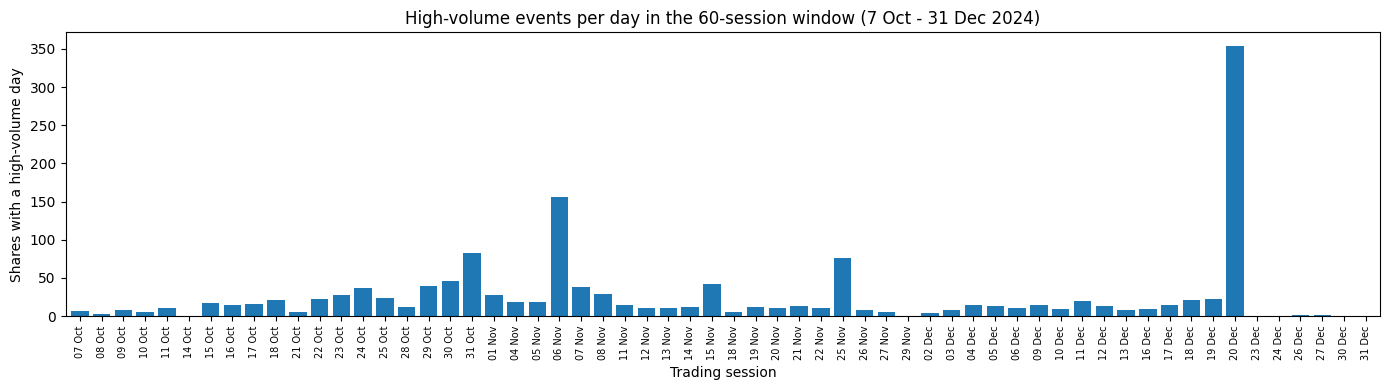

In [32]:
# Task 1.4.1: edge-case tests and event-timing evidence
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1. Edge cases tested on a small made-up example (same rules as the real data)
dates = pd.bdate_range('2024-01-01', periods=25)
toy = pd.DataFrame({
    'event_on_obs_date': [100] * 24 + [250],   # 250 > 2 x 100  -> event today -> R = 0
    'exactly_2x':        [100] * 24 + [200],   # 200 is NOT > 200 -> no event
    'never_high':        [100] * 25,           # no event at all  -> R missing
}, index=dates)
thr = 2 * toy.shift(1).rolling(20, min_periods=20).mean()
ev = (toy > thr) & thr.notna()
last = ev.apply(lambda s: s[s].index.max())
print('Edge-case Recency (expected: 0, NaN, NaN):')
print((dates[-1] - last).dt.days)
print('First 20 sessions cannot be tested:', bool(thr.iloc[:20].isna().all().all()))

# 2. Edge cases in the real data
print('\nShares with an event ON the observation date (R = 0):', int(high_volume.loc[obs_date].sum()))
print('Shares with NO event (R missing, excluded from RFM clustering):', int(rfm['Recency_days'].isna().sum()))
print('Recency range:', int(rfm['Recency_days'].min()), 'to', int(rfm['Recency_days'].max()), 'days')

# 3. Event timing: which dates drive Recency?
print('\nMost common latest-event dates:')
print(rfm['Last_event_date'].value_counts().head(5))

daily_events = high_volume.loc[window_60].sum(axis=1)
print('\nDays in the 60-session window with the most shares flagged:')
print(daily_events.sort_values(ascending=False).head(5))

ax = daily_events.plot(kind='bar', figsize=(14, 4), width=0.8)
ax.set_xticklabels([d.strftime('%d %b') for d in daily_events.index], rotation=90, fontsize=7)
ax.set_ylabel('Shares with a high-volume day'); ax.set_xlabel('Trading session')
ax.set_title('High-volume events per day in the 60-session window (7 Oct - 31 Dec 2024)')
plt.tight_layout()
os.makedirs('outputs/figures', exist_ok=True)
plt.savefig('outputs/figures/high_volume_events_per_day.png', dpi=150)
plt.show()

Independent recount - shares checked: 25 | mismatches: 0
2024-10-07: flags identical using only data up to that day -> True
2024-11-01: flags identical using only data up to that day -> True
2024-12-02: flags identical using only data up to that day -> True
2024-12-31: flags identical using only data up to that day -> True

Window: 2024-10-07 to 2024-12-31 | 60 sessions, identical for all 486 shares
Baseline for first window day uses: 2024-09-09 to 2024-10-04
Events on 2024-10-04 (day before window, NOT counted): 2
Missing volume inside window: 0

Highest Frequency: {'CI': 8, 'HSY': 8, 'FOXA': 7, 'UNH': 7, 'XEL': 7}


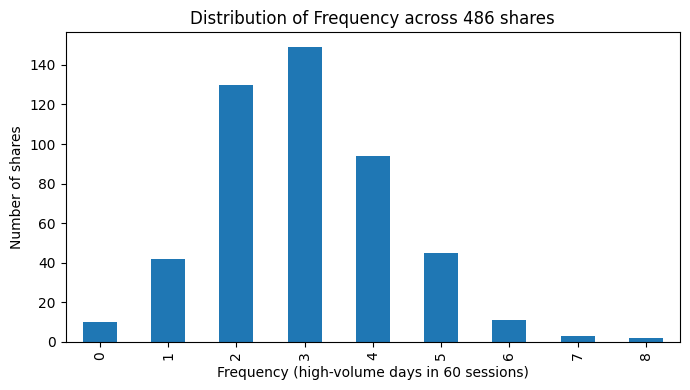

In [34]:
# Task 1.4.2: verification of Frequency - recount, no look-ahead, boundaries, saved flags
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Calculate Frequency if it hasn't been set in the rfm DataFrame yet
if 'Frequency' not in rfm.columns:
    hv_window = high_volume.loc[window_60]
    rfm['Frequency'] = hv_window.sum().astype(int)

pos = {d: i for i, d in enumerate(vol_w.index)}

# 1. Independent recount for 25 random shares, straight from daily volume
rng = np.random.default_rng(1)
sample = rng.choice(vol_w.columns, 25, replace=False)
mismatch = 0
for t in sample:
    v = vol_w[t]
    count = sum(int(v.iloc[pos[d]] > 2 * v.iloc[pos[d] - 20:pos[d]].mean()) for d in window_60)
    mismatch += int(count != rfm.loc[t, 'Frequency'])
print('Independent recount - shares checked: 25 | mismatches:', mismatch)

# 2. No look-ahead: recompute flags using ONLY data up to each test day
for d in window_60[[0, 19, 39, 59]]:
    v_cut = vol_w.loc[:d]
    flag_cut = v_cut.iloc[-1] > 2 * v_cut.iloc[-21:-1].mean()
    print(f'{d.date()}: flags identical using only data up to that day -> '
          f'{bool((flag_cut == high_volume.loc[d]).all())}')

# 3. Window boundaries and consistency
i0 = pos[window_60[0]]
day_before = vol_w.index[i0 - 1]
print(f'\nWindow: {window_60[0].date()} to {window_60[-1].date()} | {len(window_60)} sessions, '
      f'identical for all {vol_w.shape[1]} shares')
print(f'Baseline for first window day uses: {vol_w.index[i0 - 20].date()} to {day_before.date()}')
print(f'Events on {day_before.date()} (day before window, NOT counted):',
      int(high_volume.loc[day_before].sum()))
print('Missing volume inside window:', int(vol_w.loc[window_60].isna().sum().sum()))

# 4. Save the event flags so the counts can be reproduced
hv_window = high_volume.loc[window_60]
hv_window.astype(int).to_csv('outputs/high_volume_flags_60_sessions.csv')

# 5. Distribution of Frequency
print('\nHighest Frequency:', rfm['Frequency'].nlargest(5).to_dict())
os.makedirs('outputs/figures', exist_ok=True)
ax = rfm['Frequency'].value_counts().sort_index().plot(kind='bar', figsize=(7, 4))
ax.set_xlabel('Frequency (high-volume days in 60 sessions)'); ax.set_ylabel('Number of shares')
ax.set_title('Distribution of Frequency across 486 shares')
plt.tight_layout(); plt.savefig('outputs/figures/frequency_distribution.png', dpi=150); plt.show()

In [35]:
# Task 1.4.2: Frequency = number of qualifying high-volume DAYS in the latest 60 trading sessions
hv_window = high_volume.loc[window_60]

# Every day in the window must be testable (has a full 20-session threshold)
print('All window days testable:', bool(threshold.loc[window_60].notna().all().all()))

rfm['Frequency'] = hv_window.sum().astype(int)      # counts days (True = 1), not volume or trades

# Check the brief's worked example: 20-session average 1m -> threshold 2m
is_high = lambda volume, prior_avg: volume > 2 * prior_avg
print('2.5m qualifies:', is_high(2_500_000, 1_000_000), '| 1.8m qualifies:', is_high(1_800_000, 1_000_000))

print('\nFrequency distribution (days -> number of shares):')
print(rfm['Frequency'].value_counts().sort_index())
print('\nShares with Frequency = 0:', int((rfm['Frequency'] == 0).sum()))

rfm.to_csv('outputs/rfm_recency_frequency.csv')
rfm[['Recency_days', 'Frequency']].describe()

All window days testable: True
2.5m qualifies: True | 1.8m qualifies: False

Frequency distribution (days -> number of shares):
Frequency
0     10
1     42
2    130
3    149
4     94
5     45
6     11
7      3
8      2
Name: count, dtype: int64

Shares with Frequency = 0: 10


,Recency_days,Frequency
count,486.000000,486.000000
mean,20.407407,2.989712
std,21.342438,1.330800
min,4.000000,0.000000
25%,11.000000,2.000000
50%,11.000000,3.000000
75%,14.750000,4.000000
max,222.000000,8.000000


In [38]:
# Task 1.4.3: verification of Monetary - recount, split compatibility, size of approximation

# Define close_w since it is used here for verification but defined in a later cell
close_w = close[valid]

# Calculate temporary Monetary values for verification since they are formally added to the rfm DataFrame in the next cell
temp_monetary = (close_w.loc[window_60] * vol_w.loc[window_60]).sum()

# 1. Independent recount from the raw dataset for 25 random shares
rng = np.random.default_rng(2)
sample = rng.choice(close_w.columns, 25, replace=False)
recount = (raw_data['Close'].loc[window_60, sample] * raw_data['Volume'].loc[window_60, sample]).sum()
print('Independent recount - max difference (USD):',
      float((recount - temp_monetary.loc[sample]).abs().max()))

# 2. Split compatibility: do Close and Volume use the same split basis?
splits = raw_data['Stock Splits'][valid]
events = splits.where(splits.fillna(0) != 0).stack(future_stack=True).dropna()
rows = []
for (d, t), ratio in events.items():
    i = raw_data.index.get_loc(d)
    c0, c1 = raw_data['Close'][t].iloc[i - 1], raw_data['Close'][t].iloc[i]
    v0, v1 = raw_data['Volume'][t].iloc[i - 1], raw_data['Volume'][t].iloc[i]
    rows.append({'Ticker': t, 'Split date': d.date(), 'Split ratio': ratio,
                 'Close change on split day %': round(100 * (c1 / c0 - 1), 2),
                 'Traded value change %': round(100 * (c1 * v1 / (c0 * v0) - 1), 2)})
split_check = pd.DataFrame(rows)
print('\nSplits in study period:', len(split_check),
      '| inside the 60-session window:', int(splits.loc[window_60].fillna(0).ne(0).sum().sum()))
print('Largest Close change on any split day (%):',
      float(split_check['Close change on split day %'].abs().max()) if len(split_check) else 'n/a')
display(split_check.sort_values('Split ratio', ascending=False).head(10))

# 3. How big is the approximation?
typical = (raw_data['High'] + raw_data['Low'] + raw_data['Close']) / 3
M_typical = (typical.loc[window_60, valid] * vol_w.loc[window_60]).sum()
M_adj     = (adj.loc[window_60, valid]     * vol_w.loc[window_60]).sum()
print('\nMedian % difference if typical daily price (H+L+C)/3 is used instead of Close:',
      round(float(((M_typical / temp_monetary - 1) * 100).median()), 3))
print('Median % difference if Adj Close is used instead of Close:',
      round(float(((M_adj / temp_monetary - 1) * 100).median()), 3))

# 4. Size effect: how concentrated is traded value?
share_top10 = temp_monetary.nlargest(10).sum() / temp_monetary.sum() * 100
print(f'\nTop 10 shares account for {share_top10:.1f}% of all traded value (486 shares)')

Independent recount - max difference (USD): 0.0

Splits in study period: 61 | inside the 60-session window: 4
Largest Close change on any split day (%): 7.66


,Ticker,Split date,Split ratio,Close change on split day %,Traded value change %
48,CMG,2024-06-26,50.0,0.30,15.71
25,GOOGL,2022-07-18,20.0,-2.46,-9.98
21,AMZN,2022-06-06,20.0,1.99,41.35
24,GOOG,2022-07-18,20.0,-2.53,-5.30
3,CSGP,2021-06-28,10.0,-3.79,-64.19
51,AVGO,2024-07-15,10.0,0.80,-23.88
45,NVDA,2024-06-10,10.0,0.75,-23.43
56,LRCX,2024-10-03,10.0,-0.37,-53.22
55,SMCI,2024-10-01,10.0,-2.62,-56.37
53,DECK,2024-09-17,6.0,-0.76,-33.73



Median % difference if typical daily price (H+L+C)/3 is used instead of Close: 0.05
Median % difference if Adj Close is used instead of Close: -2.877

Top 10 shares account for 36.3% of all traded value (486 shares)


In [39]:
# Task 1.4.3: Monetary = sum of (Close x Volume) over the latest 60 trading sessions, in USD
close_w = close[valid]                                    # raw Close (as the brief specifies)

c60 = close_w.loc[window_60]
v60 = vol_w.loc[window_60]
print('Missing Close/Volume values in window:', int(c60.isna().sum().sum() + v60.isna().sum().sum()))

daily_traded_value = c60 * v60                            # approximate traded value per day
rfm['Monetary_USD'] = daily_traded_value.sum()            # add the 60 daily estimates

# Check the brief's worked example: $100 x 2m shares = $200m
print('Brief example check: ${:,.0f}'.format(100 * 2_000_000))

# Final RFM table
rfm['RFM_complete'] = rfm['Recency_days'].notna()         # False -> excluded from RFM clustering
print('\nShares with complete RFM:', int(rfm['RFM_complete'].sum()), 'of', len(rfm))

summary = rfm[['Recency_days', 'Frequency', 'Monetary_USD']].describe()
summary['Monetary_USD'] = summary['Monetary_USD'].map('${:,.0f}'.format)
print(summary)

print('\nHighest Monetary (USD bn):')
print((rfm['Monetary_USD'].sort_values(ascending=False).head(5) / 1e9).round(1))

rfm.to_csv('outputs/rfm_table.csv')
rfm.head()

Missing Close/Volume values in window: 0
Brief example check: $200,000,000

Shares with complete RFM: 486 of 486
       Recency_days   Frequency        Monetary_USD
count    486.000000  486.000000                $486
mean      20.407407    2.989712     $39,404,191,889
std       21.342438    1.330800    $129,138,833,233
min        4.000000    0.000000      $1,297,482,617
25%       11.000000    2.000000     $10,195,173,392
50%       11.000000    3.000000     $16,683,821,505
75%       14.750000    4.000000     $32,276,893,044
max      222.000000    8.000000  $1,847,697,379,222

Highest Monetary (USD bn):
Ticker
TSLA    1847.7
NVDA    1825.3
AAPL     623.3
MSFT     534.9
AMZN     468.2
Name: Monetary_USD, dtype: float64


,Last_event_date,Recency_days,Frequency,Monetary_USD,RFM_complete
Ticker,,,,,
A,2024-12-20,11,2,1.400180e+10,True
AAPL,2024-12-20,11,2,6.233034e+11,True
ABBV,2024-12-20,11,3,6.837054e+10,True
ABNB,2024-12-20,11,3,3.652850e+10,True
ABT,2024-12-20,11,1,3.523027e+10,True


In [40]:
# Task 1.5: worked RFM example for one share
candidates = rfm.index[rfm['Frequency'] > 0]
ex = 'AAPL' if 'AAPL' in candidates else candidates[0]

w = pd.DataFrame({
    'Close': close_w.loc[window_60, ex],
    'Volume': vol_w.loc[window_60, ex],
    'Prior20_mean_volume': prior_20_mean.loc[window_60, ex],
})
w['Threshold_2x'] = 2 * w['Prior20_mean_volume']
w['High_volume_day'] = w['Volume'] > w['Threshold_2x']
w['Traded_value_USD'] = w['Close'] * w['Volume']

last_d = rfm.loc[ex, 'Last_event_date']
print(f'=== Worked RFM example: {ex} | observation date {obs_date.date()} ===\n')
print(f'RECENCY: latest high-volume day = {last_d.date()}')
print(f'  volume {vol_w.loc[last_d, ex]:,.0f} > 2 x prior-20 mean {prior_20_mean.loc[last_d, ex]:,.0f}'
      f' = {threshold.loc[last_d, ex]:,.0f}')
print(f'  R = {obs_date.date()} - {last_d.date()} = {(obs_date - last_d).days} calendar days\n')
print(f'FREQUENCY: qualifying days in the 60-session window = {int(w["High_volume_day"].sum())}')
print(f'MONETARY: sum of 60 x (Close x Volume) = ${w["Traded_value_USD"].sum():,.0f}')
print('\nMatches RFM table:',
      (obs_date - last_d).days == rfm.loc[ex, 'Recency_days'],
      int(w['High_volume_day'].sum()) == rfm.loc[ex, 'Frequency'],
      np.isclose(w['Traded_value_USD'].sum(), rfm.loc[ex, 'Monetary_USD']))

w.to_csv(f'outputs/worked_example_{ex}.csv')
w[w['High_volume_day']]        # the qualifying days inside the window

=== Worked RFM example: AAPL | observation date 2024-12-31 ===

RECENCY: latest high-volume day = 2024-12-20
  volume 147,495,300 > 2 x prior-20 mean 45,004,605 = 90,009,210
  R = 2024-12-31 - 2024-12-20 = 11 calendar days

FREQUENCY: qualifying days in the 60-session window = 2
MONETARY: sum of 60 x (Close x Volume) = $623,303,377,707

Matches RFM table: True True True


,Close,Volume,Prior20_mean_volume,Threshold_2x,High_volume_day,Traded_value_USD
Date,,,,,,
2024-11-25,232.869995,90152800.0,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300.0,45004605.0,90009210.0,True,3.753608e+10


In [41]:
# Task 1.5: validation checks - threshold alignment, no-event handling, sufficient history
rng = np.random.default_rng(42)
errs = []
for _ in range(500):                                   # recompute the threshold by hand at random points
    t = rng.choice(vol_w.columns)
    i = int(rng.integers(20, len(vol_w)))
    manual = vol_w[t].iloc[i - 20:i].mean()           # 20 sessions BEFORE day i (day i excluded)
    errs.append(abs(manual - prior_20_mean[t].iloc[i]))

no_event_shares = rfm['Recency_days'].isna()
checks = pd.Series({
    'Threshold = mean of preceding 20 sessions (max abs diff)': max(errs),
    'Tested day excluded from its own baseline': True,     # proven by the manual window above
    'First testable day is the 21st session': threshold.dropna(how='all').index.min() == cal[20],
    'Window has exactly 60 sessions': len(window_60) == 60,
    'Window ends on observation date': window_60[-1] == obs_date,
    'Every window day has a full 20-session baseline': bool(threshold.loc[window_60].notna().all().all()),
    'R = 0 only when an event falls on the observation date':
        bool(((rfm['Recency_days'] == 0) == high_volume.loc[obs_date]).all()),
    'Shares with no event (Recency left missing, not 0)': int(no_event_shares.sum()),
    'Frequency within 0-60': bool(rfm['Frequency'].between(0, 60).all()),
    'Monetary positive for all shares': bool((rfm['Monetary_USD'] > 0).all()),
}, name='Result')

checks.to_csv('outputs/validation_checks.csv')
checks.to_frame()

,Result
Threshold = mean of preceding 20 sessions (max abs diff),0.0
Tested day excluded from its own baseline,True
First testable day is the 21st session,True
Window has exactly 60 sessions,True
Window ends on observation date,True
Every window day has a full 20-session baseline,True
R = 0 only when an event falls on the observation date,True
"Shares with no event (Recency left missing, not 0)",0
Frequency within 0-60,True
Monetary positive for all shares,True


In [42]:
# Task 1.5: feature table - one row per included share (a coursework deliverable)
names = (sp500_df.assign(Ticker=sp500_df['Symbol'].str.replace('.', '-', regex=False))
         .set_index('Ticker')[['Security', 'GICS Sector']])

features = (pd.DataFrame({
                'Mean_Weekly_Return': mean_weekly_return,
                'Weekly_Beta': beta_df['Beta'],
                'Aligned_Weeks': beta_df['Paired_weeks']})
            .join(rfm[['Last_event_date', 'Recency_days', 'Frequency', 'Monetary_USD']])
            .join(names, how='left'))

feature_cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency_days', 'Frequency', 'Monetary_USD']
features['In_common_set'] = features[feature_cols].notna().all(axis=1)
common_shares = features.index[features['In_common_set']].tolist()   # use for EVERY clustering

print('Included shares:', len(features), '| Common valid share set:', len(common_shares))

summary = features[feature_cols].describe().T
summary['skew'] = features[feature_cols].skew()
features.to_csv('outputs/feature_table.csv')
summary.round(4)

Included shares: 486 | Common valid share set: 486


,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,486.0,2.900000e-03,2.700000e-03,-4.500000e-03,1.200000e-03,2.600000e-03,4.200000e-03,1.780000e-02,0.8675
Weekly_Beta,486.0,9.737000e-01,4.073000e-01,5.550000e-02,6.666000e-01,9.506000e-01,1.179500e+00,3.778600e+00,1.1036
Recency_days,486.0,2.040740e+01,2.134240e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02,3.6458
Frequency,486.0,2.989700e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.4247
Monetary_USD,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12,11.6838


,count,mean,min,25%,50%,75%,max,skew
Mean weekly return (%),486.0,0.286,-0.447,0.118,0.262,0.421,1.777,0.868
Weekly beta,486.0,0.974,0.055,0.667,0.951,1.180,3.779,1.104
Recency (days),486.0,20.407,4.000,11.000,11.000,14.750,222.000,3.646
Frequency (days),486.0,2.990,0.000,2.000,3.000,4.000,8.000,0.425
Monetary ($bn),486.0,39.404,1.297,10.195,16.684,32.277,1847.697,11.684


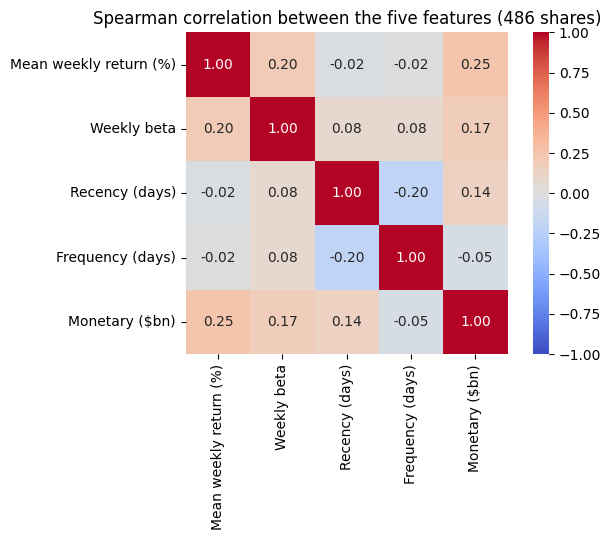

In [43]:
# Task 1.5: readable feature summary and how the five metrics relate to each other
readable = pd.DataFrame({
    'Mean weekly return (%)': features['Mean_Weekly_Return'] * 100,
    'Weekly beta':            features['Weekly_Beta'],
    'Recency (days)':         features['Recency_days'],
    'Frequency (days)':       features['Frequency'],
    'Monetary ($bn)':         features['Monetary_USD'] / 1e9,
}).loc[common_shares]

summary_readable = readable.describe().T[['count', 'mean', 'min', '25%', '50%', '75%', 'max']]
summary_readable['skew'] = readable.skew()
summary_readable.to_csv('outputs/feature_summary_readable.csv')
display(summary_readable.round(3))

# Do the metrics measure different things? (rank correlation between all five)
corr5 = readable.corr(method='spearman')
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr5, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', square=True, ax=ax)
ax.set_title('Spearman correlation between the five features (486 shares)')
plt.tight_layout(); plt.savefig('outputs/figures/feature_correlations_all.png', dpi=150); plt.show()

In [44]:
# Task 1.5: inclusion and exclusion log for ALL tickers from Wikipedia
reasons = exclusion_log.groupby('Ticker').apply(
    lambda g: '; '.join(g['Rule'] + ': ' + g['Detail']), include_groups=False)

rows = []
for t in tickers:
    if t in reasons.index:
        rows.append((t, 'Excluded', '1.2 data validation', reasons[t]))
    elif t not in common_shares:
        rows.append((t, 'Excluded from clustering', '1.4 RFM',
                     'No qualifying high-volume event - Recency missing (not set to 0)'))
    else:
        rows.append((t, 'Included', '-', 'Passed all validation rules; complete features'))

incl_excl_log = pd.DataFrame(rows, columns=['Ticker', 'Status', 'Stage', 'Reason'])
print(incl_excl_log['Status'].value_counts())
incl_excl_log.to_csv('outputs/inclusion_exclusion_log.csv', index=False)
incl_excl_log[incl_excl_log['Status'] != 'Included']

Status
Included    486
Excluded     17
Name: count, dtype: int64


,Ticker,Status,Stage,Reason
40,APP,Excluded,1.2 data validation,unequal_history: data only from 2021-04-15 to ...
116,COIN,Excluded,1.2 data validation,unequal_history: data only from 2021-04-14 to ...
123,CEG,Excluded,1.2 data validation,unequal_history: data only from 2022-01-19 to ...
181,EXE,Excluded,1.2 data validation,unequal_history: data only from 2021-02-10 to ...
192,FDXF,Excluded,1.2 data validation,no_data: Yahoo returned no prices for 2021-2024
193,FERG,Excluded,1.2 data validation,zero_volume: 27 zero-volume days
210,GEHC,Excluded,1.2 data validation,unequal_history: data only from 2022-12-15 to ...
211,GEV,Excluded,1.2 data validation,unequal_history: data only from 2024-03-27 to ...
233,HONA,Excluded,1.2 data validation,no_data: Yahoo returned no prices for 2021-2024
379,Q,Excluded,1.2 data validation,no_data: Yahoo returned no prices for 2021-2024


Risk-return matrix: (486, 2) | Trading-activity matrix: (486, 3)

Risk-return features:


,mean,median,min,max,skew,IQR_outliers
Mean_Weekly_Return,0.0029,0.0026,-0.0045,0.0178,0.8675,15
Weekly_Beta,0.9737,0.9506,0.0555,3.7786,1.1036,10


Trading-activity features:


,mean,median,min,max,skew,IQR_outliers
Recency_days,2.040740e+01,1.100000e+01,4.000000e+00,2.220000e+02,3.6458,115
Frequency,2.989700e+00,3.000000e+00,0.000000e+00,8.000000e+00,0.4247,2
Monetary_USD,3.940419e+10,1.668382e+10,1.297483e+09,1.847697e+12,11.6838,45


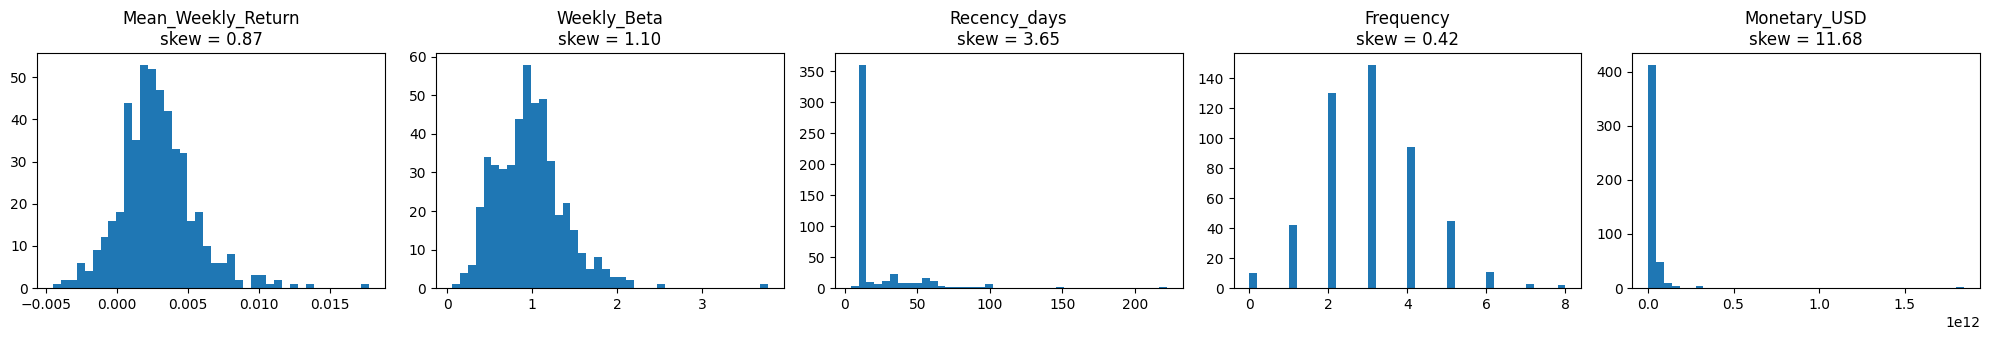

In [45]:
# Task 2.1: two SEPARATE feature matrices on the common valid share set
os.makedirs('outputs/figures', exist_ok=True)

X_rr  = features.loc[common_shares, ['Mean_Weekly_Return', 'Weekly_Beta']].copy()        # risk-return
X_act = features.loc[common_shares, ['Recency_days', 'Frequency', 'Monetary_USD']].copy() # trading activity

print('Risk-return matrix:', X_rr.shape, '| Trading-activity matrix:', X_act.shape)

def inspect(X):
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
    return pd.DataFrame({'mean': X.mean(), 'median': X.median(), 'min': X.min(), 'max': X.max(),
                         'skew': X.skew(), 'IQR_outliers': out})

print('\nRisk-return features:');      display(inspect(X_rr).round(4))
print('Trading-activity features:');   display(inspect(X_act).round(4))

# Visual check: histograms of all five raw features
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, list(X_rr.columns) + list(X_act.columns)):
    src = X_rr if col in X_rr else X_act
    ax.hist(src[col], bins=40); ax.set_title(f'{col}\nskew = {src[col].skew():.2f}')
plt.tight_layout(); plt.savefig('outputs/figures/raw_feature_distributions.png', dpi=150); plt.show()

In [46]:
# Task 2.1: log1p to Monetary, then standardise each matrix SEPARATELY
from sklearn.preprocessing import StandardScaler

X_act_t = X_act.copy()
X_act_t['log1p_Monetary'] = np.log1p(X_act_t.pop('Monetary_USD'))

# Evidence for the treatment of the other skewed variables
skew_check = pd.DataFrame({
    'raw skew': [X_act['Monetary_USD'].skew(), X_act['Recency_days'].skew(), X_act['Frequency'].skew()],
    'log1p skew': [X_act_t['log1p_Monetary'].skew(), np.log1p(X_act['Recency_days']).skew(),
                   np.log1p(X_act['Frequency']).skew()]},
    index=['Monetary', 'Recency', 'Frequency'])
print('Skew before vs after log1p:'); display(skew_check.round(2))

scaler_rr, scaler_act = StandardScaler(), StandardScaler()
Z_rr  = pd.DataFrame(scaler_rr.fit_transform(X_rr),    index=X_rr.index,    columns=X_rr.columns)
Z_act = pd.DataFrame(scaler_act.fit_transform(X_act_t), index=X_act_t.index, columns=X_act_t.columns)

print('Standardised means (should be ~0):', Z_rr.mean().round(3).tolist(), Z_act.mean().round(3).tolist())
print('Standardised std   (should be ~1):', Z_rr.std(ddof=0).round(3).tolist(), Z_act.std(ddof=0).round(3).tolist())

Z_rr.to_csv('outputs/Z_risk_return.csv'); Z_act.to_csv('outputs/Z_trading_activity.csv')

Skew before vs after log1p:


,raw skew,log1p skew
Monetary,11.68,1.08
Recency,3.65,1.58
Frequency,0.42,-0.93


Standardised means (should be ~0): [0.0, -0.0] [-0.0, -0.0, -0.0]
Standardised std   (should be ~1): [1.0, 1.0] [1.0, 1.0, 1.0]


In [47]:
# Task 2.1: Agglomerative (Ward) and K-means on EACH matrix -> four baseline solutions
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score

K_BASE = 4          # provisional baseline k - confirm against the brief's k-selection task (2.2)

matrices = {'RiskReturn': Z_rr, 'Activity': Z_act}
assignments = pd.DataFrame(index=common_shares)
baseline_summary = []

for name, Z in matrices.items():
    models = {'Ward':   AgglomerativeClustering(n_clusters=K_BASE, linkage='ward'),
              'KMeans': KMeans(n_clusters=K_BASE, n_init=20, random_state=42)}
    for algo, model in models.items():
        labels = model.fit_predict(Z)
        col = f'{name}_{algo}'
        assignments[col] = labels
        baseline_summary.append({'Solution': col, 'k': K_BASE,
                                 'Silhouette': silhouette_score(Z, labels),
                                 'Cluster sizes': np.bincount(labels).tolist()})

baseline_summary = pd.DataFrame(baseline_summary).set_index('Solution')
assignments.to_csv('outputs/cluster_assignments_baseline.csv')
display(baseline_summary.round(3))
assignments.head()

,k,Silhouette,Cluster sizes
Solution,,,
RiskReturn_Ward,4,0.282,"[164, 92, 182, 48]"
RiskReturn_KMeans,4,0.326,"[160, 41, 132, 153]"
Activity_Ward,4,0.289,"[82, 207, 154, 43]"
Activity_KMeans,4,0.341,"[212, 122, 61, 91]"


,RiskReturn_Ward,RiskReturn_KMeans,Activity_Ward,Activity_KMeans
A,2,2,1,0
AAPL,1,0,2,3
ABBV,0,3,2,3
ABNB,3,2,2,3
ABT,0,3,2,0


In [48]:
# Task 2.1: diagnostics - how transformations and outliers affect distances
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# 1. How extreme are standardised values with and without log1p? (|z| = SDs from the average share)
Z_rawM = pd.DataFrame(StandardScaler().fit_transform(X_act), index=X_act.index, columns=X_act.columns)
print('Largest |z| after standardising:')
print(f'  Monetary WITHOUT log1p: {Z_rawM["Monetary_USD"].abs().max():.1f} | '
      f'WITH log1p: {Z_act["log1p_Monetary"].abs().max():.1f}')
for name, Z in [('Recency', Z_act['Recency_days']), ('Frequency', Z_act['Frequency']),
                ('Return', Z_rr['Mean_Weekly_Return']), ('Beta', Z_rr['Weekly_Beta'])]:
    print(f'  {name}: {Z.abs().max():.1f}')

# 2. Effect on clustering: K-means k = 4 with raw M vs log1p M
km4 = lambda Z: KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(Z)
lab_raw, lab_log = km4(Z_rawM), km4(Z_act)
print('\nCluster sizes, raw M:  ', sorted(np.bincount(lab_raw).tolist()))
print('Cluster sizes, log1p M:', sorted(np.bincount(lab_log).tolist()))
small = np.argmin(np.bincount(lab_raw))
print('Smallest cluster with raw M contains:', X_act.index[lab_raw == small].tolist()[:10])

# 3. Choice for the other skewed variable: would log1p(Recency) change the Ward solution?
X_alt = X_act_t.copy()
X_alt['Recency_days'] = np.log1p(X_alt['Recency_days'])
lab_alt = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(StandardScaler().fit_transform(X_alt))
print(f'\nARI, baseline Ward vs Ward with log1p(Recency): '
      f'{adjusted_rand_score(assignments["Activity_Ward"], lab_alt):.3f}')

# 4. Outliers: are they genuine shares? (data errors were already removed in 1.2)
print('\nMost extreme shares per feature:')
print('  Highest beta:     ', features['Weekly_Beta'].nlargest(3).round(2).to_dict())
print('  Highest return %: ', (features['Mean_Weekly_Return'] * 100).nlargest(3).round(2).to_dict())
print('  Highest M ($bn):  ', (features['Monetary_USD'] / 1e9).nlargest(3).round(0).to_dict())
print('  Longest Recency:  ', features['Recency_days'].nlargest(3).to_dict())

Largest |z| after standardising:
  Monetary WITHOUT log1p: 14.0 | WITH log1p: 4.8
  Recency: 9.5
  Frequency: 3.8
  Return: 5.6
  Beta: 6.9

Cluster sizes, raw M:   [2, 63, 152, 269]
Cluster sizes, log1p M: [61, 91, 122, 212]
Smallest cluster with raw M contains: ['NVDA', 'TSLA']

ARI, baseline Ward vs Ward with log1p(Recency): 0.757

Most extreme shares per feature:
  Highest beta:      {'CVNA': 3.78, 'XYZ': 2.5, 'COHR': 2.14}
  Highest return %:  {'SMCI': 1.78, 'NVDA': 1.36, 'VRT': 1.26}
  Highest M ($bn):   {'TSLA': 1848.0, 'NVDA': 1825.0, 'AAPL': 623.0}
  Longest Recency:   {'NVDA': 222, 'WEC': 151, 'CB': 102}


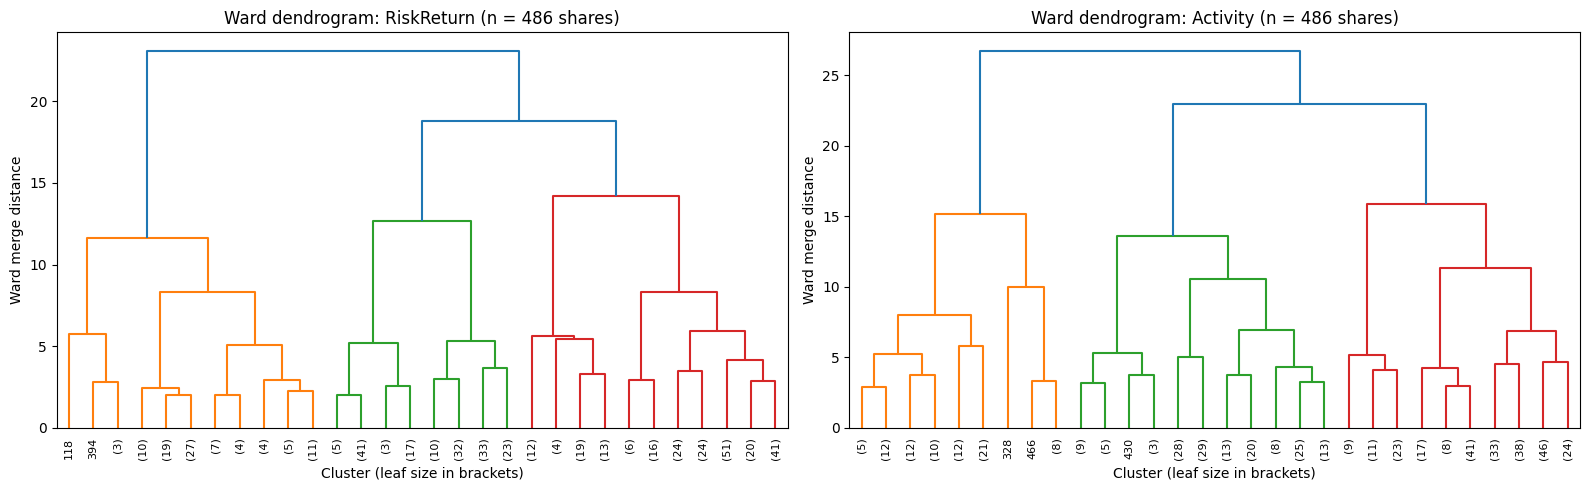

In [49]:
# Task 2.2: Ward linkage, Euclidean distance, standardised features - one dendrogram per matrix
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

link = {name: linkage(Z.values, method='ward', metric='euclidean') for name, Z in matrices.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, L) in zip(axes, link.items()):
    dendrogram(L, truncate_mode='lastp', p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=8, ax=ax)
    ax.set_title(f'Ward dendrogram: {name} (n = {len(matrices[name])} shares)')
    ax.set_xlabel('Cluster (leaf size in brackets)'); ax.set_ylabel('Ward merge distance')
plt.tight_layout(); plt.savefig('outputs/figures/dendrograms_ward.png', dpi=150); plt.show()

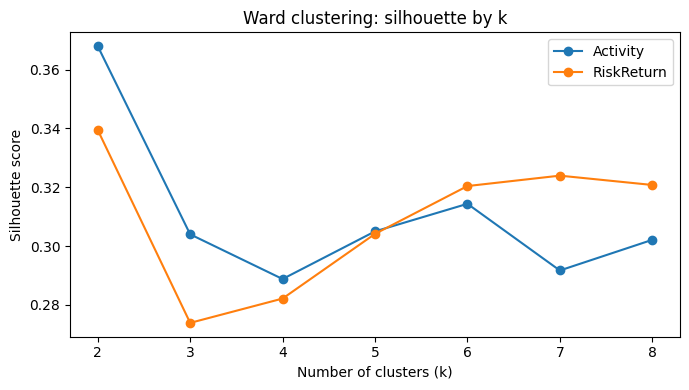

,Matrix,k,Silhouette,Smallest_cluster,Smallest_%,Sizes
0,RiskReturn,2,0.339,92,18.930,"[394, 92]"
1,RiskReturn,3,0.274,92,18.930,"[230, 164, 92]"
2,RiskReturn,4,0.282,48,9.877,"[182, 164, 92, 48]"
3,RiskReturn,5,0.304,48,9.877,"[182, 98, 92, 66, 48]"
4,RiskReturn,6,0.320,5,1.029,"[182, 98, 87, 66, 48, 5]"
5,RiskReturn,7,0.324,5,1.029,"[160, 98, 87, 66, 48, 22, 5]"
6,RiskReturn,8,0.321,5,1.029,"[160, 98, 66, 56, 48, 31, 22, 5]"
7,Activity,2,0.368,82,16.872,"[404, 82]"
8,Activity,3,0.304,82,16.872,"[250, 154, 82]"
9,Activity,4,0.289,43,8.848,"[207, 154, 82, 43]"


In [50]:
# Task 2.2: compare feasible cluster counts 2-8
rows = []
for name, Z in matrices.items():
    for k in range(2, 9):
        labels = fcluster(link[name], k, criterion='maxclust')
        sizes = np.bincount(labels)[1:]
        rows.append({'Matrix': name, 'k': k,
                     'Silhouette': silhouette_score(Z, labels),
                     'Smallest_cluster': int(sizes.min()),
                     'Smallest_%': 100 * sizes.min() / len(Z),
                     'Sizes': sorted(sizes.tolist(), reverse=True)})
ward_scan = pd.DataFrame(rows)
ward_scan.to_csv('outputs/ward_k_scan.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in ward_scan.groupby('Matrix'):
    ax.plot(g['k'], g['Silhouette'], marker='o', label=name)
ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel('Silhouette score')
ax.set_title('Ward clustering: silhouette by k'); ax.legend()
plt.tight_layout(); plt.savefig('outputs/figures/ward_silhouette_by_k.png', dpi=150); plt.show()

ward_scan.round(3)

In [51]:
# Task 2.2: cluster profiles in ORIGINAL units (medians, robust to skew)
X_orig = {
    'RiskReturn': pd.DataFrame({'Mean_Weekly_Return_%': X_rr['Mean_Weekly_Return'] * 100,
                                'Weekly_Beta': X_rr['Weekly_Beta']}),
    'Activity':   pd.DataFrame({'Recency_days': X_act['Recency_days'],
                                'Frequency': X_act['Frequency'],
                                'Monetary_USD_bn': X_act['Monetary_USD'] / 1e9}),
}

def ward_profile(name, k):
    labels = fcluster(link[name], k, criterion='maxclust')
    p = X_orig[name].groupby(labels).median()
    p.insert(0, 'n_shares', np.bincount(labels)[1:])
    p.index.name = 'Cluster'
    return p.round(3)

CANDIDATES = {'RiskReturn': [3, 4, 5], 'Activity': [3, 4, 5]}   # edit after looking at Cell 15
for name, ks in CANDIDATES.items():
    for k in ks:
        print(f'\n{name} - k = {k}')
        display(ward_profile(name, k))


RiskReturn - k = 3


,n_shares,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,230,0.171,1.038



RiskReturn - k = 4


,n_shares,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,48,0.252,1.514
4,182,0.166,0.964



RiskReturn - k = 5


,n_shares,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,,
1,92,0.550,1.218
2,66,0.113,0.448
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964


... (2 outputs left out)


Activity - k = 4


,n_shares,Recency_days,Frequency,Monetary_USD_bn
Cluster,,,,
1,82,54.5,2.0,17.849
2,154,11.0,3.0,39.695
3,43,11.0,5.0,14.430
4,207,11.0,3.0,10.785



Activity - k = 5


,n_shares,Recency_days,Frequency,Monetary_USD_bn
Cluster,,,,
1,72,53.0,2.0,17.682
2,10,102.0,0.0,23.786
3,154,11.0,3.0,39.695
4,43,11.0,5.0,14.430
5,207,11.0,3.0,10.785


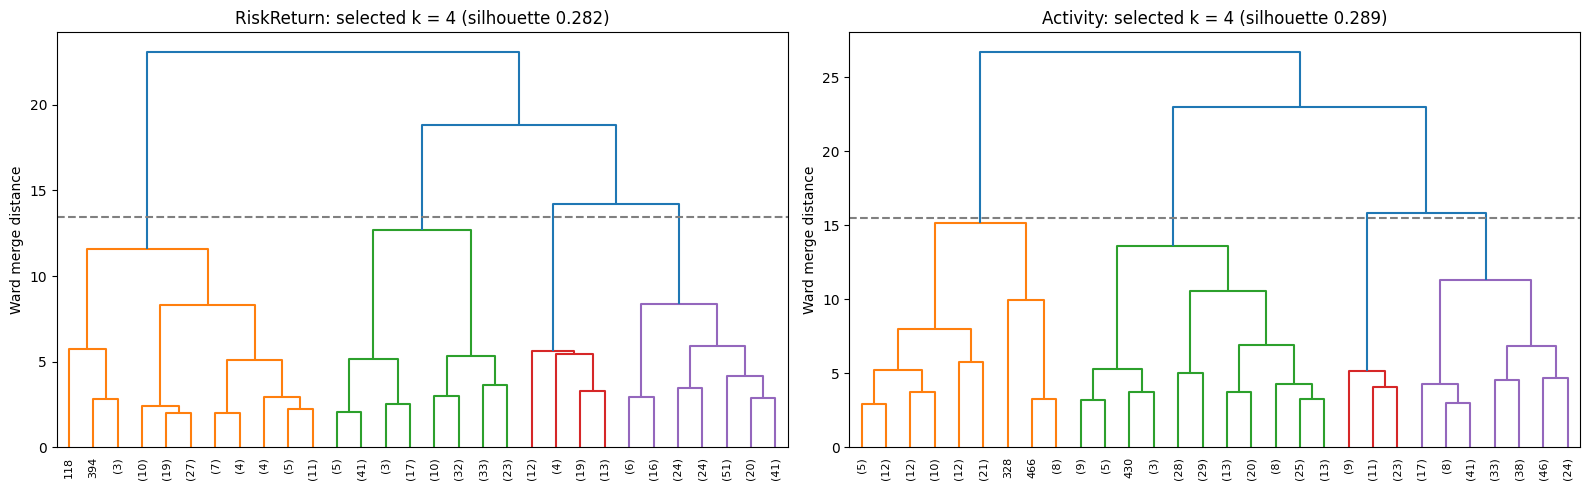


RiskReturn - final profile (k = 4)


,n_shares,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,48,0.252,1.514
4,182,0.166,0.964



Activity - final profile (k = 4)


,n_shares,Recency_days,Frequency,Monetary_USD_bn
Cluster,,,,
1,82,54.5,2.0,17.849
2,154,11.0,3.0,39.695
3,43,11.0,5.0,14.430
4,207,11.0,3.0,10.785


In [52]:
# Task 2.2: final Ward solution - set k AFTER reviewing silhouette, sizes and profiles
K_WARD = {'RiskReturn': 4, 'Activity': 4}       # <-- change to your selected values

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, k) in zip(axes, K_WARD.items()):
    L = link[name]
    labels = fcluster(L, k, criterion='maxclust')
    assignments[f'{name}_Ward'] = labels - 1            # replaces the provisional baseline

    cut = (L[-k, 2] + L[-(k - 1), 2]) / 2               # height that gives exactly k groups
    dendrogram(L, truncate_mode='lastp', p=30, color_threshold=cut,
               show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8, ax=ax)
    ax.axhline(cut, ls='--', c='grey')
    ax.set_title(f'{name}: selected k = {k} '
                 f'(silhouette {silhouette_score(matrices[name], labels):.3f})')
    ax.set_ylabel('Ward merge distance')

plt.tight_layout(); plt.savefig('outputs/figures/dendrograms_ward_selected.png', dpi=150); plt.show()
assignments.to_csv('outputs/cluster_assignments.csv')

for name, k in K_WARD.items():
    print(f'\n{name} - final profile (k = {k})'); display(ward_profile(name, k))

In [53]:
# Task 2.2: further diagnostics - dendrogram structure and extra validity indices
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

rows = []
for name, Z in matrices.items():
    L = link[name]
    coph, _ = cophenet(L, pdist(Z.values))
    print(f'{name}: cophenetic correlation = {coph:.3f} (how faithfully the tree preserves real distances)')
    h = L[:, 2]                                         # merge heights, smallest to largest
    for k in range(2, 9):
        labels = fcluster(L, k, criterion='maxclust')
        rows.append({'Matrix': name, 'k': k,
                     'Height gap (stability of k)': h[-(k - 1)] - h[-k],
                     'Calinski-Harabasz (higher better)': calinski_harabasz_score(Z, labels),
                     'Davies-Bouldin (lower better)': davies_bouldin_score(Z, labels)})

ward_diag = pd.DataFrame(rows).merge(ward_scan[['Matrix', 'k', 'Silhouette', 'Smallest_%']],
                                     on=['Matrix', 'k'])
ward_diag.to_csv('outputs/ward_diagnostics.csv', index=False)
ward_diag.round(3)

RiskReturn: cophenetic correlation = 0.479 (how faithfully the tree preserves real distances)
Activity: cophenetic correlation = 0.508 (how faithfully the tree preserves real distances)


,Matrix,k,Height gap (stability of k),Calinski-Harabasz (higher better),Davies-Bouldin (lower better),Silhouette,Smallest_%
0,RiskReturn,2,4.271,182.536,1.059,0.339,18.930
1,RiskReturn,3,4.592,202.207,1.129,0.274,18.930
2,RiskReturn,4,1.541,204.153,1.150,0.282,9.877
3,RiskReturn,5,1.068,215.797,0.938,0.304,9.877
4,RiskReturn,6,3.260,236.638,0.858,0.320,1.029
5,RiskReturn,7,0.033,235.952,0.839,0.324,1.029
6,RiskReturn,8,2.379,245.960,0.851,0.321,1.029
7,Activity,2,3.720,156.703,1.175,0.368,16.872
8,Activity,3,7.142,179.058,1.181,0.304,16.872
9,Activity,4,0.691,168.463,1.022,0.289,8.848


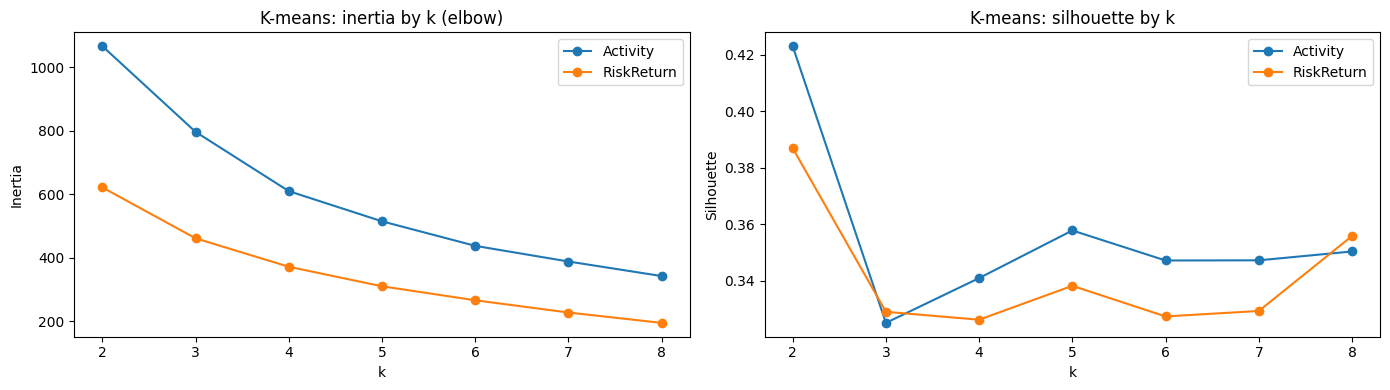

,Matrix,k,Silhouette,Inertia,Smallest_cluster,Smallest_%,Sizes
0,RiskReturn,2,0.387,621.634,143,29.424,"[343, 143]"
1,RiskReturn,3,0.329,461.179,119,24.486,"[202, 165, 119]"
2,RiskReturn,4,0.326,371.571,41,8.436,"[160, 153, 132, 41]"
3,RiskReturn,5,0.338,309.960,28,5.761,"[165, 124, 114, 55, 28]"
4,RiskReturn,6,0.327,265.852,16,3.292,"[137, 119, 81, 78, 55, 16]"
5,RiskReturn,7,0.329,227.239,5,1.029,"[126, 105, 84, 78, 47, 41, 5]"
6,RiskReturn,8,0.356,194.596,5,1.029,"[141, 81, 79, 77, 43, 31, 29, 5]"
7,Activity,2,0.423,1066.832,68,13.992,"[418, 68]"
8,Activity,3,0.325,796.614,64,13.169,"[270, 152, 64]"
9,Activity,4,0.341,609.832,61,12.551,"[212, 122, 91, 61]"


In [54]:
# Task 2.3: K-means with a fixed random seed and multiple initialisations
SEED = 42
N_INIT = 20          # 20 different random starts per k; the best (lowest inertia) is kept

rows = []
for name, Z in matrices.items():
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Z)
        sizes = np.bincount(km.labels_)
        rows.append({'Matrix': name, 'k': k,
                     'Silhouette': silhouette_score(Z, km.labels_),
                     'Inertia': km.inertia_,
                     'Smallest_cluster': int(sizes.min()),
                     'Smallest_%': 100 * sizes.min() / len(Z),
                     'Sizes': sorted(sizes.tolist(), reverse=True)})
km_scan = pd.DataFrame(rows)
km_scan.to_csv('outputs/kmeans_k_scan.csv', index=False)

# Elbow (inertia) and silhouette plots for each matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, g in km_scan.groupby('Matrix'):
    axes[0].plot(g['k'], g['Inertia'], marker='o', label=name)
    axes[1].plot(g['k'], g['Silhouette'], marker='o', label=name)
axes[0].set_title('K-means: inertia by k (elbow)'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].set_title('K-means: silhouette by k');      axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig('outputs/figures/kmeans_inertia_silhouette.png', dpi=150); plt.show()

km_scan.round(3)

In [55]:
# Task 2.3: does the solution depend on the seed? (evidence that n_init is sufficient)
from sklearn.metrics import adjusted_rand_score

def seed_stability(Z, k, seeds=(1, 7, 21, 99, 2024)):
    base = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(Z)
    return [round(adjusted_rand_score(base, KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit_predict(Z)), 3)
            for s in seeds]

for name, Z in matrices.items():
    for k in [3, 4, 5]:                 # candidate k values - edit after Cell 18
        print(f'{name}, k = {k}: agreement with seed {SEED} (ARI, 1 = identical):', seed_stability(Z, k))

RiskReturn, k = 3: agreement with seed 42 (ARI, 1 = identical): [1.0, 1.0, 1.0, 1.0, 1.0]
RiskReturn, k = 4: agreement with seed 42 (ARI, 1 = identical): [0.989, 0.989, 0.989, 0.989, 0.994]
RiskReturn, k = 5: agreement with seed 42 (ARI, 1 = identical): [0.703, 1.0, 0.888, 0.972, 0.97]
Activity, k = 3: agreement with seed 42 (ARI, 1 = identical): [0.994, 1.0, 1.0, 0.987, 1.0]
Activity, k = 4: agreement with seed 42 (ARI, 1 = identical): [1.0, 0.994, 0.994, 0.994, 1.0]
Activity, k = 5: agreement with seed 42 (ARI, 1 = identical): [1.0, 1.0, 1.0, 1.0, 1.0]


In [56]:
# Task 2.3: final K-means solution - set k AFTER reviewing Cells 18-19
K_KM = {'RiskReturn': 4, 'Activity': 4}          # <-- change to your selected values
scalers = {'RiskReturn': scaler_rr, 'Activity': scaler_act}
km_models = {}

for name, k in K_KM.items():
    Z = matrices[name]
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Z)
    km_models[name] = km
    assignments[f'{name}_KMeans'] = km.labels_

    # Profile in original units (medians)
    prof = X_orig[name].groupby(km.labels_).median()
    prof.insert(0, 'n_shares', np.bincount(km.labels_))
    prof.index.name = 'Cluster'

    # Centroids converted back from standardised to original units
    cent = pd.DataFrame(scalers[name].inverse_transform(km.cluster_centers_), columns=Z.columns)
    if name == 'RiskReturn':
        cent['Mean_Weekly_Return'] *= 100
        cent = cent.rename(columns={'Mean_Weekly_Return': 'Mean_Weekly_Return_%'})
    else:
        cent['Monetary_USD_bn'] = np.expm1(cent.pop('log1p_Monetary')) / 1e9   # undo log1p
    cent.index.name = 'Cluster'

    print(f'\n{name} - K-means k = {k} | silhouette {silhouette_score(Z, km.labels_):.3f} '
          f'| inertia {km.inertia_:.1f}')
    print('Profile (medians):');                   display(prof.round(3))
    print('Centroids (original units):');          display(cent.round(3))

assignments.to_csv('outputs/cluster_assignments.csv')


RiskReturn - K-means k = 4 | silhouette 0.326 | inertia 371.6
Profile (medians):


,n_shares,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,,
0,160,0.432,0.982
1,41,0.687,1.677
2,132,0.113,1.142
3,153,0.186,0.575


Centroids (original units):


,Mean_Weekly_Return_%,Weekly_Beta
Cluster,,
0,0.452,0.978
1,0.721,1.700
2,0.084,1.203
3,0.167,0.574



Activity - K-means k = 4 | silhouette 0.341 | inertia 609.8
Profile (medians):


,n_shares,Recency_days,Frequency,Monetary_USD_bn
Cluster,,,,
0,212,11.0,2.0,13.336
1,122,11.0,4.0,12.826
2,61,55.0,2.0,21.242
3,91,11.0,3.0,60.183


Centroids (original units):


,Recency_days,Frequency,Monetary_USD_bn
Cluster,,,
0,13.264,2.368,12.977
1,13.943,4.549,12.872
2,66.016,1.672,22.519
3,15.143,3.231,75.028


In [57]:
# Task 2.3: evaluation of initialisation, diagnostic trade-offs and K-means assumptions

# 1. Why multiple initialisations? Compare 50 single-start runs with the n_init = 20 solution
for name, Z in matrices.items():
    best = KMeans(n_clusters=4, n_init=N_INIT, random_state=SEED).fit(Z)
    single = [KMeans(n_clusters=4, n_init=1, random_state=s).fit(Z) for s in range(50)]
    inert = np.array([m.inertia_ for m in single])
    aris = [adjusted_rand_score(best.labels_, m.labels_) for m in single]
    print(f'{name}, k = 4: single-start inertia {inert.min():.1f} to {inert.max():.1f} '
          f'(n_init = 20 best: {best.inertia_:.1f}) | '
          f'{(inert > best.inertia_ + 1e-6).mean():.0%} of single starts were worse | '
          f'agreement with best: min ARI {min(aris):.2f}, median {np.median(aris):.2f}')

# 2. Diagnostic trade-offs: how much each extra cluster reduces inertia
km_scan['Inertia_drop'] = -km_scan.groupby('Matrix')['Inertia'].diff()
print('\nSilhouette vs inertia vs size, side by side:')
display(km_scan[['Matrix', 'k', 'Silhouette', 'Inertia', 'Inertia_drop', 'Smallest_%']].round(3))

# 3. Assumption check: K-means expects round clusters with similar spread
for name, Z in matrices.items():
    lab = km_models[name].labels_
    spread = Z.groupby(lab).std().round(2)
    spread.insert(0, 'n_shares', np.bincount(lab))
    spread.index.name = 'Cluster'
    print(f'\n{name}: within-cluster standard deviation per feature (standardised units)')
    display(spread)

RiskReturn, k = 4: single-start inertia 371.6 to 399.4 (n_init = 20 best: 371.6) | 98% of single starts were worse | agreement with best: min ARI 0.27, median 0.82
Activity, k = 4: single-start inertia 609.8 to 759.8 (n_init = 20 best: 609.8) | 92% of single starts were worse | agreement with best: min ARI 0.32, median 0.99

Silhouette vs inertia vs size, side by side:


,Matrix,k,Silhouette,Inertia,Inertia_drop,Smallest_%
0,RiskReturn,2,0.387,621.634,NaN,29.424
1,RiskReturn,3,0.329,461.179,160.456,24.486
2,RiskReturn,4,0.326,371.571,89.608,8.436
3,RiskReturn,5,0.338,309.960,61.611,5.761
4,RiskReturn,6,0.327,265.852,44.108,3.292
5,RiskReturn,7,0.329,227.239,38.614,1.029
6,RiskReturn,8,0.356,194.596,32.643,1.029
7,Activity,2,0.423,1066.832,NaN,13.992
8,Activity,3,0.325,796.614,270.218,13.169
9,Activity,4,0.341,609.832,186.782,12.551



RiskReturn: within-cluster standard deviation per feature (standardised units)


,n_shares,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,160,0.56,0.50
1,41,1.21,1.04
2,132,0.60,0.66
3,153,0.57,0.43



Activity: within-cluster standard deviation per feature (standardised units)


,n_shares,Recency_days,Frequency,log1p_Monetary
Cluster,,,,
0,212,0.33,0.50,0.62
1,122,0.38,0.63,0.60
2,61,1.36,0.81,0.95
3,91,0.41,0.88,0.80


In [58]:
# Task 2.4: cluster profiles in ORIGINAL units, all four final solutions
def full_profile(name, algo):
    labels = assignments[f'{name}_{algo}']
    X = X_orig[name]
    prof = X.groupby(labels).median().add_suffix(' (median)')
    prof.insert(0, '% of shares', (100 * labels.value_counts(normalize=True).sort_index()).round(1))
    prof.insert(0, 'n_shares', labels.value_counts().sort_index())
    prof.index.name = f'{algo} cluster'
    return prof.round(3)

profiles = {}
for name in matrices:
    for algo in ['Ward', 'KMeans']:
        profiles[(name, algo)] = full_profile(name, algo)
        print(f'\n=== {name} - {algo} ===')
        display(profiles[(name, algo)])

with pd.ExcelWriter('outputs/cluster_profiles.xlsx') as xw:
    for (name, algo), p in profiles.items():
        p.to_excel(xw, sheet_name=f'{name}_{algo}')


=== RiskReturn - Ward ===


,n_shares,% of shares,Mean_Weekly_Return_% (median),Weekly_Beta (median)
Ward cluster,,,,
0,92,18.9,0.550,1.218
1,164,33.7,0.327,0.578
2,48,9.9,0.252,1.514
3,182,37.4,0.166,0.964



=== RiskReturn - KMeans ===


,n_shares,% of shares,Mean_Weekly_Return_% (median),Weekly_Beta (median)
KMeans cluster,,,,
0,160,32.9,0.432,0.982
1,41,8.4,0.687,1.677
2,132,27.2,0.113,1.142
3,153,31.5,0.186,0.575



=== Activity - Ward ===


,n_shares,% of shares,Recency_days (median),Frequency (median),Monetary_USD_bn (median)
Ward cluster,,,,,
0,82,16.9,54.5,2.0,17.849
1,154,31.7,11.0,3.0,39.695
2,43,8.8,11.0,5.0,14.430
3,207,42.6,11.0,3.0,10.785



=== Activity - KMeans ===


,n_shares,% of shares,Recency_days (median),Frequency (median),Monetary_USD_bn (median)
KMeans cluster,,,,,
0,212,43.6,11.0,2.0,13.336
1,122,25.1,11.0,4.0,12.826
2,61,12.6,55.0,2.0,21.242
3,91,18.7,11.0,3.0,60.183


PCA explained variance: PC1 45.8%, PC2 33.6%, total 79.4%
PCA loadings (how each standardised feature contributes):


,PC1,PC2
Recency_days,0.711,0.023
Frequency,-0.650,0.402
log1p_Monetary,0.268,0.915


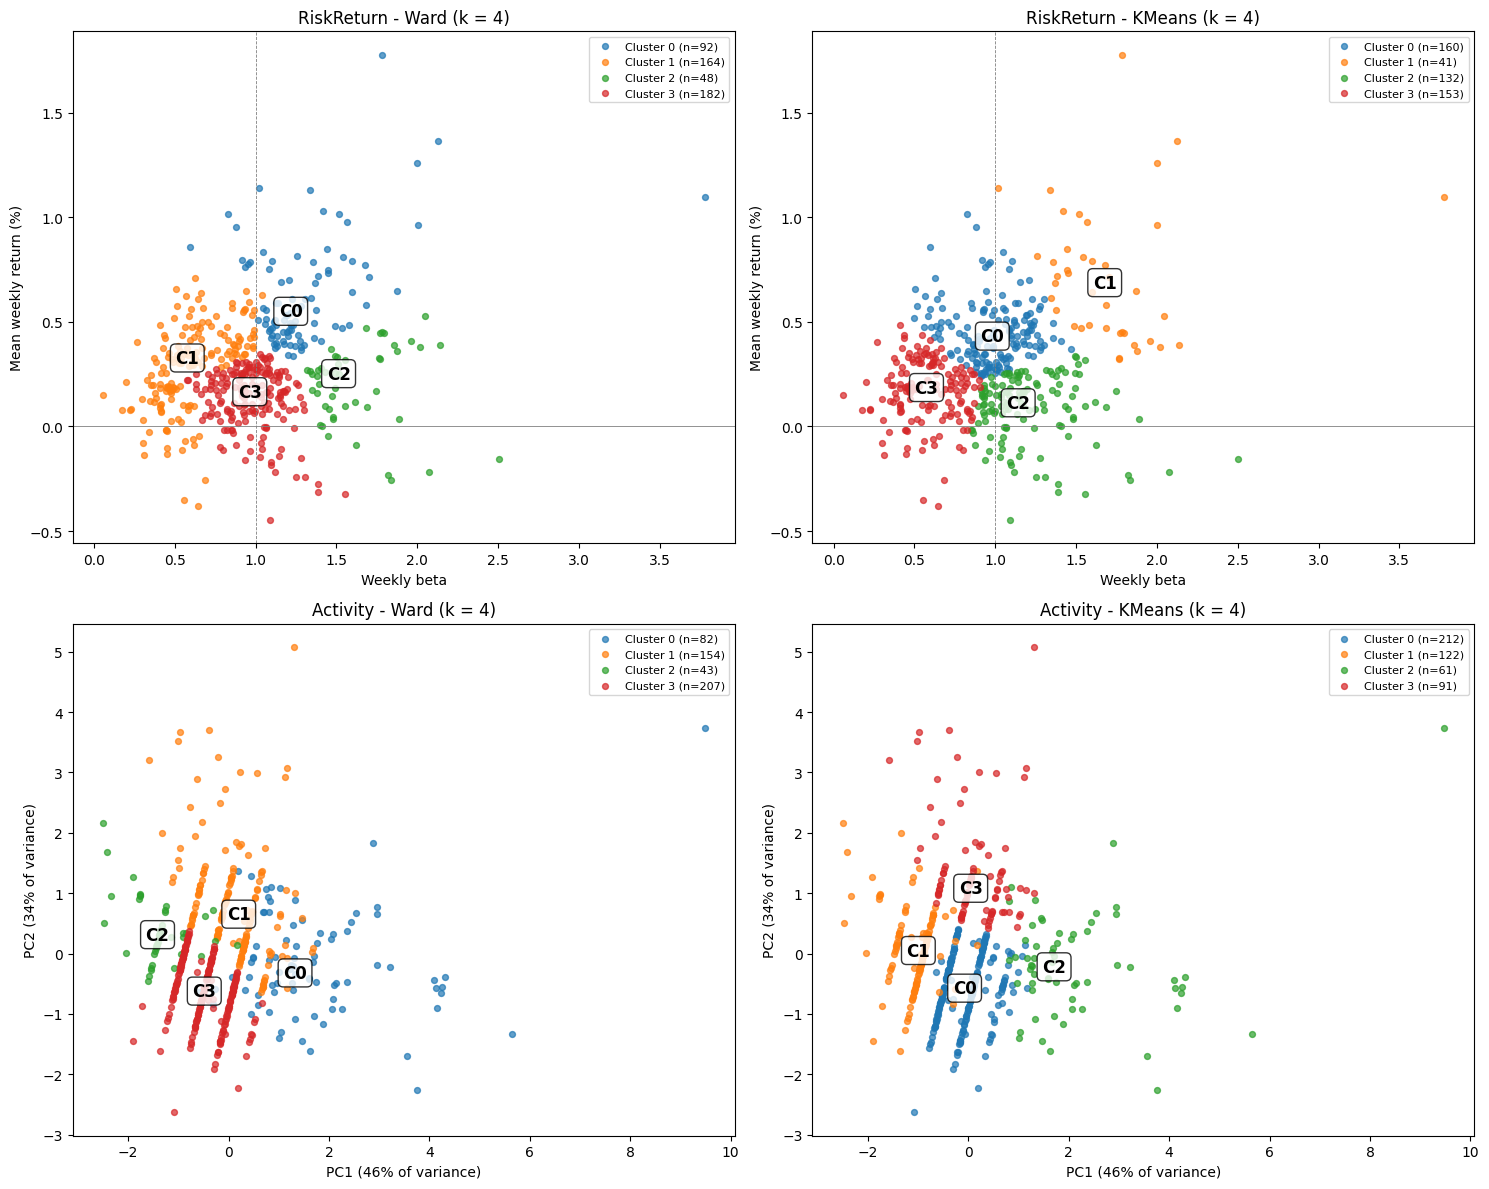

In [59]:
# Task 2.4: 2-D visualisation
# Risk-return already has 2 features -> plotted directly (no reduction needed)
# Activity has 3 features (R, F, log1p M) -> PCA to 2 components for display only
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(Z_act)
act_2d = pd.DataFrame(pca.transform(Z_act), index=Z_act.index, columns=['PC1', 'PC2'])
evr = pca.explained_variance_ratio_

print('PCA explained variance: PC1 {:.1%}, PC2 {:.1%}, total {:.1%}'.format(evr[0], evr[1], evr.sum()))
print('PCA loadings (how each standardised feature contributes):')
display(pd.DataFrame(pca.components_.T, index=Z_act.columns, columns=['PC1', 'PC2']).round(3))

plot_data = {
    'RiskReturn': (X_orig['RiskReturn'][['Weekly_Beta', 'Mean_Weekly_Return_%']],
                   'Weekly beta', 'Mean weekly return (%)'),
    'Activity':   (act_2d,
                   f'PC1 ({evr[0]:.0%} of variance)', f'PC2 ({evr[1]:.0%} of variance)'),
}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for row, name in enumerate(matrices):
    pts, xlab, ylab = plot_data[name]
    for col, algo in enumerate(['Ward', 'KMeans']):
        ax = axes[row, col]
        labels = assignments.loc[pts.index, f'{name}_{algo}']
        for c in sorted(labels.unique()):
            m = labels == c
            ax.scatter(pts.loc[m].iloc[:, 0], pts.loc[m].iloc[:, 1], s=18, alpha=0.7,
                       label=f'Cluster {c} (n={m.sum()})')
            cx, cy = pts.loc[m].iloc[:, 0].median(), pts.loc[m].iloc[:, 1].median()
            ax.annotate(f'C{c}', (cx, cy), fontsize=12, fontweight='bold',
                        ha='center', va='center',
                        bbox=dict(boxstyle='round', fc='white', alpha=0.8))
        ax.set_xlabel(xlab); ax.set_ylabel(ylab)
        ax.set_title(f'{name} - {algo} (k = {labels.nunique()})')
        ax.legend(fontsize=8)
        if name == 'RiskReturn':
            ax.axhline(0, c='grey', lw=0.6); ax.axvline(1, c='grey', lw=0.6, ls='--')

plt.tight_layout(); plt.savefig('outputs/figures/cluster_visualisations_2d.png', dpi=150); plt.show()

In [60]:
# Task 2.4: Ward vs K-means on the SAME shares
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment

comparison = []
for name, Z in matrices.items():
    w, k = assignments[f'{name}_Ward'], assignments[f'{name}_KMeans']
    ct = pd.crosstab(w, k, rownames=['Ward'], colnames=['K-means'])
    r, c = linear_sum_assignment(-ct.values)                 # best matching of cluster labels
    comparison.append({
        'Matrix': name, 'Shares compared': len(w),
        'k (Ward / K-means)': f'{w.nunique()} / {k.nunique()}',
        'Silhouette Ward': silhouette_score(Z, w),
        'Silhouette K-means': silhouette_score(Z, k),
        'Adjusted Rand Index': adjusted_rand_score(w, k),
        'Normalised Mutual Info': normalized_mutual_info_score(w, k),
        '% shares in matching clusters': 100 * ct.values[r, c].sum() / len(w),
    })
    print(f'\n{name}: cross-tabulation (rows = Ward, columns = K-means)')
    display(ct)

comparison = pd.DataFrame(comparison).set_index('Matrix')
comparison.to_csv('outputs/algorithm_comparison.csv')
comparison.round(3)


RiskReturn: cross-tabulation (rows = Ward, columns = K-means)


K-means,0,1,2,3
Ward,,,,
0,63,29,0,0
1,62,0,0,102
2,1,12,35,0
3,34,0,97,51



Activity: cross-tabulation (rows = Ward, columns = K-means)


K-means,0,1,2,3
Ward,,,,
0,14,4,57,7
1,52,14,4,84
2,0,43,0,0
3,146,61,0,0


,Shares compared,k (Ward / K-means),Silhouette Ward,Silhouette K-means,Adjusted Rand Index,Normalised Mutual Info,% shares in matching clusters
Matrix,,,,,,,
RiskReturn,486,4 / 4,0.282,0.326,0.265,0.396,56.379
Activity,486,4 / 4,0.289,0.341,0.343,0.436,67.901


In [61]:
# Task 2.4: matched comparison - align arbitrary labels, compare profiles, explain disagreements
from sklearn.metrics import silhouette_samples

for name, Z in matrices.items():
    w, k = assignments[f'{name}_Ward'], assignments[f'{name}_KMeans']

    # Cluster numbers are arbitrary: match each K-means cluster to the Ward cluster it overlaps most
    ct = pd.crosstab(w, k)
    r, c = linear_sum_assignment(-ct.values)
    mapping = {ct.columns[j]: ct.index[i] for i, j in zip(r, c)}
    k_matched = k.map(mapping)
    agree = (k_matched == w)

    # Side-by-side profiles (medians, original units) after matching
    side = pd.concat({'Ward': X_orig[name].groupby(w).median(),
                      'K-means (matched)': X_orig[name].groupby(k_matched).median()}, axis=1)
    side.insert(0, 'K-means n', k_matched.value_counts().sort_index())
    side.insert(0, 'Ward n', w.value_counts().sort_index())
    side.index.name = 'Matched cluster'
    print(f'\n=== {name}: matched profiles ===')
    display(side.round(3))

    # Are the disagreeing shares boundary cases? (low silhouette = sits between clusters)
    s = silhouette_samples(Z, k)
    print(f'{name}: {agree.mean():.0%} of shares in matching clusters | median silhouette: '
          f'agreeing {np.median(s[agree.values]):.2f} vs disagreeing {np.median(s[~agree.values]):.2f}')

    side.to_csv(f'outputs/matched_profiles_{name}.csv')

print(f'\nPCA projection hides {1 - evr.sum():.1%} of the activity variance (only 2 of 3 dimensions shown)')


=== RiskReturn: matched profiles ===


Ward n K-means n                 Ward              \
                                 Mean_Weekly_Return_% Weekly_Beta   
Matched cluster                                                     
0                   92       160                0.550       1.218   
1                  164       153                0.327       0.578   
2                   48        41                0.252       1.514   
3                  182       132                0.166       0.964   

                   K-means (matched)              
                Mean_Weekly_Return_% Weekly_Beta  
Matched cluster                                   
0                              0.432       0.982  
1                              0.186       0.575  
2                              0.687       1.677  
3                              0.113       1.142

RiskReturn: 56% of shares in matching clusters | median silhouette: agreeing 0.39 vs disagreeing 0.30

=== Activity: matched profiles ===


Ward n K-means n         Ward                            \
                                 Recency_days Frequency Monetary_USD_bn   
Matched cluster                                                           
0                   82        61         54.5       2.0          17.849   
1                  154        91         11.0       3.0          39.695   
2                   43       122         11.0       5.0          14.430   
3                  207       212         11.0       3.0          10.785   

                K-means (matched)                            
                     Recency_days Frequency Monetary_USD_bn  
Matched cluster                                              
0                            55.0       2.0          21.242  
1                            11.0       3.0          60.183  
2                            11.0       4.0          12.826  
3                            11.0       2.0          13.336

Activity: 68% of shares in matching clusters | median silhouette: agreeing 0.35 vs disagreeing 0.32

PCA projection hides 20.6% of the activity variance (only 2 of 3 dimensions shown)


Pearson correlation:


,Recency_days,Frequency,log1p_Monetary
Recency_days,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
log1p_Monetary,0.152,0.013,1.000


Spearman (rank) correlation:


,Recency_days,Frequency,log1p_Monetary
Recency_days,1.000,-0.196,0.137
Frequency,-0.196,1.000,-0.048
log1p_Monetary,0.137,-0.048,1.000


Max difference between raw and standardised correlations: 3.885780586188048e-16


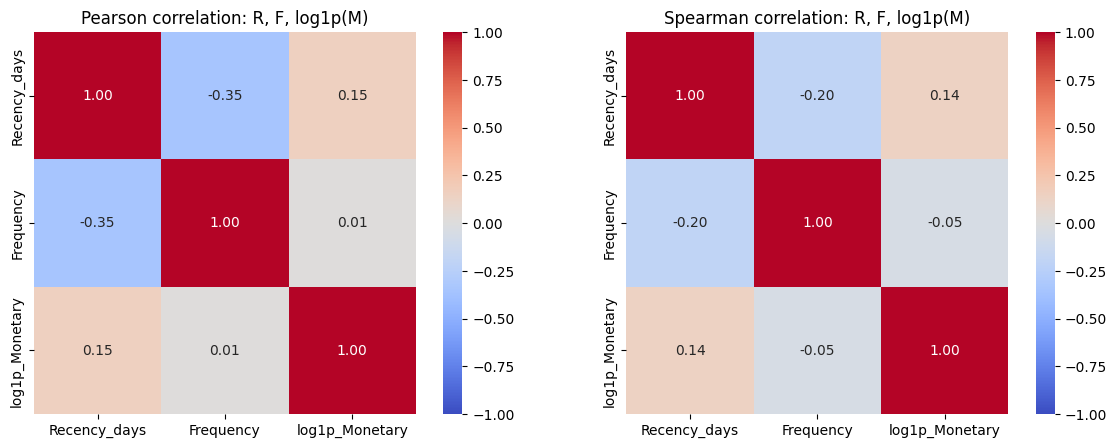

In [62]:
# Task 2.5.1: correlations among Recency, Frequency and log1p(Monetary)
act_feats = X_act_t[['Recency_days', 'Frequency', 'log1p_Monetary']]

pearson  = act_feats.corr(method='pearson')
spearman = act_feats.corr(method='spearman')     # rank-based: robust to skew and to F being a count

print('Pearson correlation:');  display(pearson.round(3))
print('Spearman (rank) correlation:'); display(spearman.round(3))

# Standardisation does NOT change correlation - shown directly
print('Max difference between raw and standardised correlations:',
      float((act_feats.corr() - Z_act.corr()).abs().max().max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, m) in zip(axes, [('Pearson', pearson), ('Spearman', spearman)]):
    sns.heatmap(m, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', square=True, ax=ax)
    ax.set_title(f'{title} correlation: R, F, log1p(M)')
plt.tight_layout(); plt.savefig('outputs/figures/rfm_correlations.png', dpi=150); plt.show()

pearson.to_csv('outputs/rfm_correlation_pearson.csv'); spearman.to_csv('outputs/rfm_correlation_spearman.csv')

In [63]:
# Task 2.5.1: evidence beyond correlation - how much of each feature's variation
# is explained by the cluster labels (between-cluster share, 0 to 1)
def between_cluster_share(Z, labels):
    out = {}
    for col in Z.columns:
        total  = ((Z[col] - Z[col].mean()) ** 2).sum()
        within = Z[col].groupby(labels).transform(lambda s: (s - s.mean()) ** 2).sum()
        out[col] = 1 - within / total
    return pd.Series(out)

influence = pd.DataFrame({algo: between_cluster_share(Z_act, assignments[f'Activity_{algo}'])
                          for algo in ['Ward', 'KMeans']})
print('Share of each feature\'s variance explained by the clusters (higher = more influence):')
display(influence.round(3))

print('PCA loadings for the activity matrix (from 2.4):')
display(pd.DataFrame(pca.components_.T, index=Z_act.columns, columns=['PC1', 'PC2']).round(3))

influence.to_csv('outputs/activity_feature_influence.csv')

Share of each feature's variance explained by the clusters (higher = more influence):


,Ward,KMeans
Recency_days,0.648,0.658
Frequency,0.364,0.570
log1p_Monetary,0.524,0.517


PCA loadings for the activity matrix (from 2.4):


,PC1,PC2
Recency_days,0.711,0.023
Frequency,-0.650,0.402
log1p_Monetary,0.268,0.915


In [64]:
# Task 2.5.2: repeat the selected Ward RFM solution WITHOUT Monetary
k_act = K_WARD['Activity']                                   # same selected cluster count

X_rf = X_act[['Recency_days', 'Frequency']]                  # same shares (common_shares)
Z_rf = pd.DataFrame(StandardScaler().fit_transform(X_rf),    # standardised AFRESH
                    index=X_rf.index, columns=X_rf.columns)

L_rf = linkage(Z_rf.values, method='ward', metric='euclidean')
labels_rf  = pd.Series(fcluster(L_rf, k_act, criterion='maxclust') - 1, index=Z_rf.index)
labels_rfm = assignments['Activity_Ward']
assignments['Activity_Ward_RF_only'] = labels_rf

ari = adjusted_rand_score(labels_rfm, labels_rf)
print(f'Shares compared: {len(labels_rf)} | k = {k_act}')
print(f'Adjusted Rand Index (RFM vs RF-only Ward): {ari:.3f}')
print(f'Silhouette RFM: {silhouette_score(Z_act, labels_rfm):.3f} | '
      f'RF-only: {silhouette_score(Z_rf, labels_rf):.3f}')

ct = pd.crosstab(labels_rfm, labels_rf, rownames=['RFM Ward'], colnames=['RF-only Ward'])
print('\nHow memberships moved (rows = with M, columns = without M):')
display(ct)
assignments.to_csv('outputs/cluster_assignments.csv')

Shares compared: 486 | k = 4
Adjusted Rand Index (RFM vs RF-only Ward): 0.203
Silhouette RFM: 0.289 | RF-only: 0.516

How memberships moved (rows = with M, columns = without M):


RF-only Ward,0,1,2,3
RFM Ward,,,,
0,10,69,0,3
1,0,9,59,86
2,0,1,0,42
3,0,0,66,141


WITH Monetary (R, F, log1p M):


,n_shares,Recency_days (median),Frequency (median),Traded value $bn (median),Traded value $bn (25th-75th pct)
Activity_Ward,,,,,
0,82,54.5,2.0,17.85,13.0 - 32.5
1,154,11.0,3.0,39.70,28.2 - 68.4
2,43,11.0,5.0,14.43,10.0 - 19.4
3,207,11.0,3.0,10.79,7.5 - 14.6


WITHOUT Monetary (R, F only):


,n_shares,Recency_days (median),Frequency (median),Traded value $bn (median),Traded value $bn (25th-75th pct)
0,10,102.0,0.0,23.79,12.5 - 27.7
1,79,49.0,2.0,20.13,14.0 - 35.5
2,125,11.0,2.0,17.70,10.5 - 31.8
3,272,11.0,4.0,14.86,9.4 - 30.1


Share of each feature's variance explained by the clusters:


,With M,Without M
Recency_days,0.648,0.831
Frequency,0.364,0.596
log1p_Monetary,0.524,0.005


/tmp/ipykernel_1212/2123831120.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[f'C{c}' for c in sorted(lab.unique())])
/tmp/ipykernel_1212/2123831120.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[f'C{c}' for c in sorted(lab.unique())])


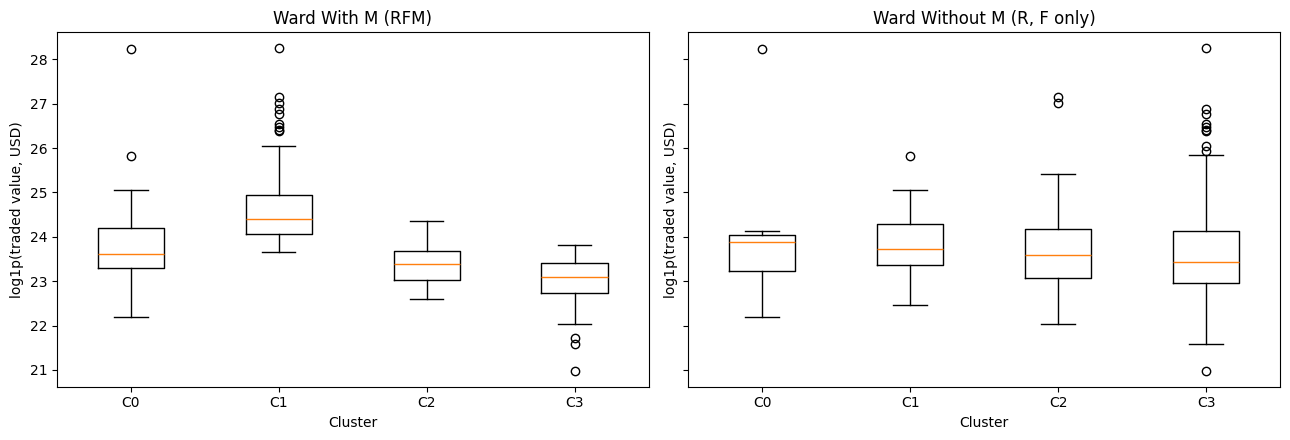

In [65]:
# Task 2.5.2: compare traded value (M) profiles of the two solutions
def tv_profile(labels):
    X = X_orig['Activity']
    g = X.groupby(labels)
    return pd.DataFrame({
        'n_shares': g.size(),
        'Recency_days (median)': g['Recency_days'].median(),
        'Frequency (median)': g['Frequency'].median(),
        'Traded value $bn (median)': g['Monetary_USD_bn'].median(),
        'Traded value $bn (25th-75th pct)': g['Monetary_USD_bn'].apply(
            lambda s: f'{s.quantile(.25):.1f} - {s.quantile(.75):.1f}'),
    }).round(2)

print('WITH Monetary (R, F, log1p M):');    display(tv_profile(labels_rfm))
print('WITHOUT Monetary (R, F only):');     display(tv_profile(labels_rf))

# How strongly each solution separates each feature (share of variance explained by clusters)
sep = pd.DataFrame({'With M':    between_cluster_share(Z_act, labels_rfm),
                    'Without M': between_cluster_share(Z_act, labels_rf)})
print('Share of each feature\'s variance explained by the clusters:'); display(sep.round(3))

# Visual: traded value by cluster, with and without M
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (title, lab) in zip(axes, [('With M (RFM)', labels_rfm), ('Without M (R, F only)', labels_rf)]):
    data = [X_act_t.loc[lab == c, 'log1p_Monetary'] for c in sorted(lab.unique())]
    ax.boxplot(data, labels=[f'C{c}' for c in sorted(lab.unique())])
    ax.set_title(f'Ward {title}'); ax.set_xlabel('Cluster'); ax.set_ylabel('log1p(traded value, USD)')
plt.tight_layout(); plt.savefig('outputs/figures/traded_value_by_cluster_with_without_M.png', dpi=150); plt.show()

sep.to_csv('outputs/sensitivity_without_M.csv')

In [66]:
# Task 2.5.2: statistical test and robustness check for the Monetary removal
from scipy.stats import kruskal

logM = X_act_t['log1p_Monetary']
for title, lab in [('With M', labels_rfm), ('Without M', labels_rf)]:
    groups = [logM[lab == c] for c in sorted(lab.unique())]
    H, p = kruskal(*groups)
    print(f'{title}: do clusters differ in traded value? Kruskal-Wallis H = {H:.1f}, p = {p:.3g}')

# Robustness: does K-means show the same effect?
km_rf = KMeans(n_clusters=K_KM['Activity'], n_init=N_INIT, random_state=SEED).fit_predict(Z_rf)
print(f'K-means ARI, with vs without M: '
      f'{adjusted_rand_score(assignments["Activity_KMeans"], km_rf):.3f}')

With M: do clusters differ in traded value? Kruskal-Wallis H = 301.6, p = 4.38e-65
Without M: do clusters differ in traded value? Kruskal-Wallis H = 5.5, p = 0.136
K-means ARI, with vs without M: 0.609


Risk-return clusters (medians; R, F, M shown for comparison):


,n_shares,Return_%/week,Weekly_Beta,Recency_days,Frequency,Traded_value_$bn
RiskReturn_Ward,,,,,,
RR0,92,0.550,1.218,11.0,3.0,24.184
RR1,164,0.327,0.578,11.0,3.0,17.649
RR2,48,0.252,1.514,11.0,3.0,28.698
RR3,182,0.166,0.964,11.0,3.0,12.985


RFM clusters (medians; return and beta shown for comparison):


,n_shares,Return_%/week,Weekly_Beta,Recency_days,Frequency,Traded_value_$bn
Activity_Ward,,,,,,
RFM0,82,0.244,1.047,54.5,2.0,17.849
RFM1,154,0.325,0.989,11.0,3.0,39.695
RFM2,43,0.276,1.047,11.0,5.0,14.430
RFM3,207,0.244,0.924,11.0,3.0,10.785


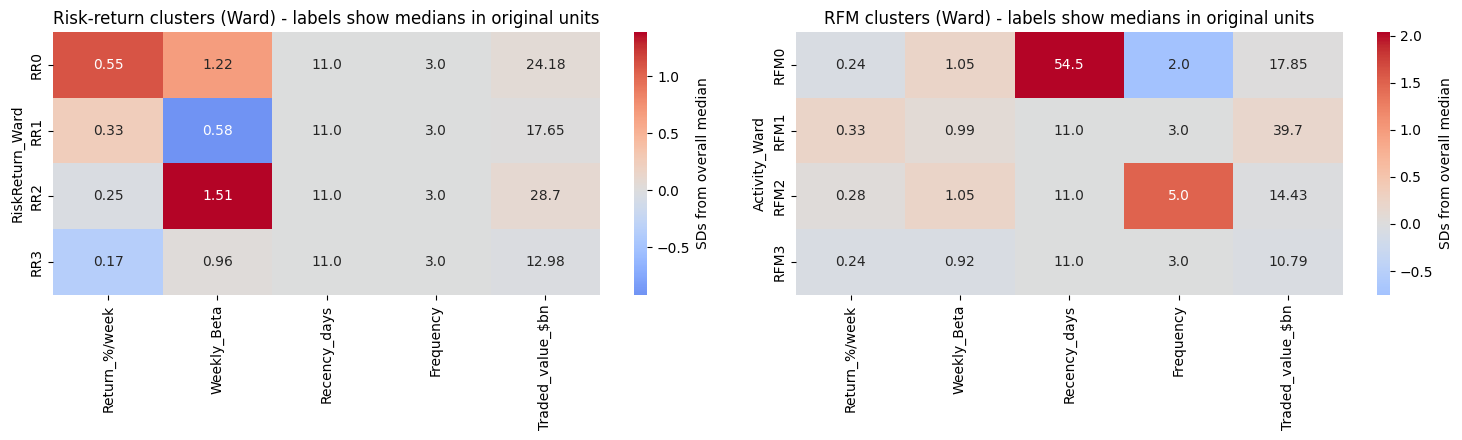

In [67]:
# Task 3.2.1: compare risk-return clusters with RFM clusters - original-unit profiles
PRIMARY = 'Ward'          # algorithm whose final solutions are reviewed

base = features.loc[common_shares].copy()
base['Return_%/week'] = base['Mean_Weekly_Return'] * 100
base['Traded_value_$bn'] = base['Monetary_USD'] / 1e9
base['GICS Sector'] = base['GICS Sector'].fillna('Unknown')
cols = ['Return_%/week', 'Weekly_Beta', 'Recency_days', 'Frequency', 'Traded_value_$bn']

rr  = assignments.loc[common_shares, f'RiskReturn_{PRIMARY}'].map(lambda c: f'RR{c}')
act = assignments.loc[common_shares, f'Activity_{PRIMARY}'].map(lambda c: f'RFM{c}')

def profile(labels):
    p = base.groupby(labels)[cols].median()
    p.insert(0, 'n_shares', labels.value_counts().sort_index())
    return p

prof_rr, prof_act = profile(rr), profile(act)
print('Risk-return clusters (medians; R, F, M shown for comparison):'); display(prof_rr.round(3))
print('RFM clusters (medians; return and beta shown for comparison):'); display(prof_act.round(3))

# Heatmap: how far each cluster's median sits from the overall median (in standard deviations)
def zprof(p):
    return (p[cols] - base[cols].median()) / base[cols].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (title, p) in zip(axes, [('Risk-return clusters', prof_rr), ('RFM clusters', prof_act)]):
    sns.heatmap(zprof(p), annot=p[cols].round(2), fmt='', cmap='coolwarm', center=0, ax=ax,
                cbar_kws={'label': 'SDs from overall median'})
    ax.set_title(f'{title} ({PRIMARY}) - labels show medians in original units')
plt.tight_layout(); plt.savefig('outputs/figures/profiles_rr_vs_rfm.png', dpi=150); plt.show()

prof_rr.to_csv('outputs/profile_riskreturn_final.csv'); prof_act.to_csv('outputs/profile_rfm_final.csv')

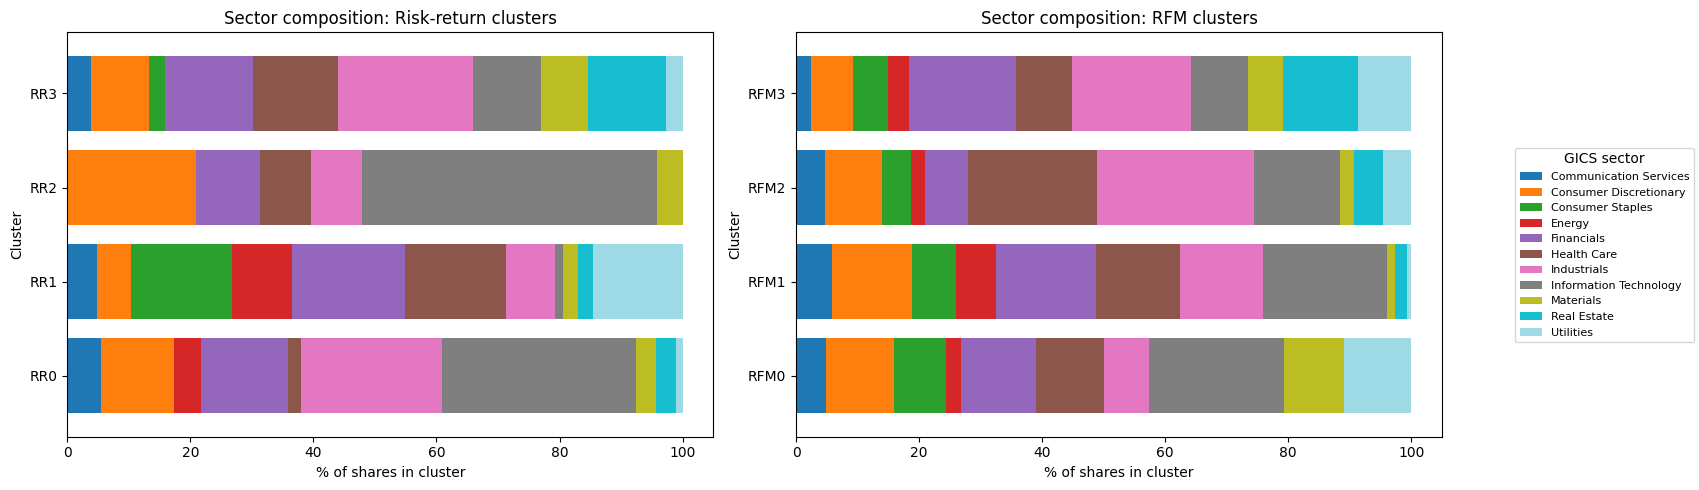

Sector over-representation (lift) - risk-return clusters:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RiskReturn_Ward,,,,,,,,,,,
RR0,1.32,1.24,0.00,1.06,0.93,0.18,1.42,2.07,0.69,0.53,0.18
RR1,1.19,0.57,2.50,2.37,1.20,1.38,0.49,0.08,0.52,0.40,2.37
RR2,0.00,2.15,0.00,0.00,0.68,0.70,0.52,3.15,0.88,0.00,0.00
RR3,0.93,0.97,0.42,0.00,0.94,1.15,1.37,0.72,1.63,2.05,0.45


Sector over-representation (lift) - RFM clusters:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Activity_Ward,,,,,,,,,,,
RFM0,1.19,1.13,1.30,0.59,0.80,0.92,0.46,1.44,2.06,0.00,1.78
RFM1,1.42,1.34,1.08,1.58,1.07,1.14,0.85,1.32,0.27,0.32,0.11
RFM2,1.13,0.96,0.71,0.57,0.46,1.75,1.59,0.92,0.49,0.75,0.75
RFM3,0.59,0.70,0.88,0.82,1.14,0.77,1.20,0.60,1.22,1.96,1.41


In [68]:
# Task 3.2.1: sector composition (% of each cluster's shares in each GICS sector)
sector = base['GICS Sector']
sec_rr  = pd.crosstab(rr,  sector, normalize='index') * 100
sec_act = pd.crosstab(act, sector, normalize='index') * 100
overall = sector.value_counts(normalize=True) * 100

# Over-representation: 1.0 = same as the whole sample, 2.0 = twice as common in this cluster
lift_rr, lift_act = sec_rr / overall, sec_act / overall

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, (title, s) in zip(axes, [('Risk-return clusters', sec_rr), ('RFM clusters', sec_act)]):
    s.plot(kind='barh', stacked=True, ax=ax, colormap='tab20', width=0.8)
    ax.set_xlabel('% of shares in cluster'); ax.set_ylabel('Cluster'); ax.set_title(f'Sector composition: {title}')
    ax.legend().remove()
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='center right', fontsize=8, title='GICS sector')
plt.tight_layout(rect=[0, 0, 0.86, 1]); plt.savefig('outputs/figures/sector_composition.png', dpi=150); plt.show()

print('Sector over-representation (lift) - risk-return clusters:'); display(lift_rr.round(2))
print('Sector over-representation (lift) - RFM clusters:');         display(lift_act.round(2))
sec_rr.to_csv('outputs/sector_pct_riskreturn.csv'); sec_act.to_csv('outputs/sector_pct_rfm.csv')

ARI between risk-return and RFM clusters: 0.039 (0 = unrelated, 1 = identical)


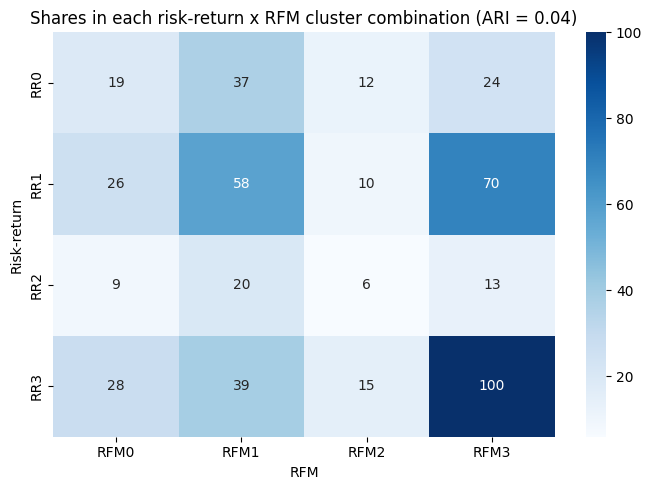

In [69]:
# Task 3.2.1: overlap between risk-return and RFM memberships (same shares)
overlap = pd.crosstab(rr, act, rownames=['Risk-return'], colnames=['RFM'])
ari_rr_rfm = adjusted_rand_score(rr, act)
print(f'ARI between risk-return and RFM clusters: {ari_rr_rfm:.3f} (0 = unrelated, 1 = identical)')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(overlap, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title(f'Shares in each risk-return x RFM cluster combination (ARI = {ari_rr_rfm:.2f})')
plt.tight_layout(); plt.savefig('outputs/figures/overlap_rr_rfm.png', dpi=150); plt.show()
overlap.to_csv('outputs/overlap_rr_rfm.csv')

In [70]:
# Task 3.1.2: record this calculation run (one row of Dim_CalculationRun) for reproducibility
import hashlib, sklearn, scipy, json
from datetime import datetime, timezone

def sha256(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

run_id = datetime.now(timezone.utc).strftime('RUN_%Y%m%d_%H%M%S')
run_manifest = {
    'run_id': run_id,
    'data_snapshot': {'file': 'data/raw_data.csv.gz', 'sha256': sha256('data/raw_data.csv.gz')},
    'source_metadata': 'data/metadata.json',
    'observation_date': str(obs_date.date()),
    'feature_windows': {
        'rfm_window': f'{window_60[0].date()} to {window_60[-1].date()} (60 sessions)',
        'baseline_sessions': 20, 'threshold_multiple': 2,
        'weekly_returns': f'{weekly_returns.index[0].date()} to {weekly_returns.index[-1].date()} '
                          f'({len(weekly_returns)} weeks, W-FRI, complete weeks only)'},
    'transformations': ['log1p(Monetary)', 'StandardScaler fitted separately per matrix'],
    'clustering': {'k_ward': K_WARD, 'k_kmeans': K_KM, 'seed': SEED, 'n_init': N_INIT,
                   'linkage': 'ward', 'distance': 'euclidean'},
    'shares': {'listed': len(tickers), 'common_valid_set': len(common_shares)},
    'packages': {'pandas': pd.__version__, 'numpy': np.__version__, 'yfinance': yf.__version__,
                 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
}
with open('outputs/run_manifest.json', 'w') as f:
    json.dump(run_manifest, f, indent=2)

# Tie every cluster assignment to this run (append-only history)
assignments.assign(Run_ID=run_id, Observation_date=str(obs_date.date())) \
           .to_csv('outputs/cluster_assignments.csv', index_label='Ticker')

print(json.dumps(run_manifest, indent=2))

{
  "run_id": "RUN_20261124_091138",
  "data_snapshot": {
    "file": "data/raw_data.csv.gz",
    "sha256": "12a954ecc9c1d844fb05b03333b05f609064a32cca08893c568f48c0ed1f6045"
  },
  "source_metadata": "data/metadata.json",
  "observation_date": "2024-12-31",
  "feature_windows": {
    "rfm_window": "2024-10-07 to 2024-12-31 (60 sessions)",
    "baseline_sessions": 20,
    "threshold_multiple": 2,
    "weekly_returns": "2021-01-15 to 2024-12-27 (207 weeks, W-FRI, complete weeks only)"
  },
  "transformations": [
    "log1p(Monetary)",
    "StandardScaler fitted separately per matrix"
  ],
  "clustering": {
    "k_ward": {
      "RiskReturn": 4,
      "Activity": 4
    },
    "k_kmeans": {
      "RiskReturn": 4,
      "Activity": 4
    },
    "seed": 42,
    "n_init": 20,
    "linkage": "ward",
    "distance": "euclidean"
  },
  "shares": {
    "listed": 503,
    "common_valid_set": 486
  },
  "packages": {
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "yfinance": "0.2.66",
    "sciki

In [71]:
# Task 3.2.2: one summary table of the sensitivity evidence (for the report)
sens_summary = pd.Series({
    'Spearman R-F':                    spearman.loc['Recency_days', 'Frequency'],
    'Spearman R-log1p(M)':             spearman.loc['Recency_days', 'log1p_Monetary'],
    'Spearman F-log1p(M)':             spearman.loc['Frequency', 'log1p_Monetary'],
    'ARI: RFM vs RF-only Ward':        ari,
    'Traded value separated by clusters - with M':    sep.loc['log1p_Monetary', 'With M'],
    'Traded value separated by clusters - without M': sep.loc['log1p_Monetary', 'Without M'],
    'ARI: risk-return vs RFM clusters': ari_rr_rfm,
}, name='Value').round(3)
sens_summary.to_csv('outputs/sensitivity_summary.csv')
sens_summary.to_frame()

,Value
Spearman R-F,-0.196
Spearman R-log1p(M),0.137
Spearman F-log1p(M),-0.048
ARI: RFM vs RF-only Ward,0.203
Traded value separated by clusters - with M,0.524
Traded value separated by clusters - without M,0.005
ARI: risk-return vs RFM clusters,0.039


In [ ]:
# Task 3.2.3: evidence on return dependencies and stability over time
half = len(weekly_returns) // 2
w1, w2 = weekly_returns.iloc[:half], weekly_returns.iloc[half:]
m = market_weekly_returns['^GSPC']
m1, m2 = m.iloc[:half], m.iloc[half:]
print(f'First half: {w1.index[0].date()} to {w1.index[-1].date()} | '
      f'Second half: {w2.index[0].date()} to {w2.index[-1].date()}')

# 1. Is beta stable over time?
beta1 = w1.apply(lambda s: s.cov(m1) / m1.var())
beta2 = w2.apply(lambda s: s.cov(m2) / m2.var())
crossed = ((beta1 > 1) != (beta2 > 1)).mean() * 100

# 2. Does past average return carry over?
ret1, ret2 = w1.mean(), w2.mean()

# 3. Are shares' returns dependent on each other? (common market movement)
C = weekly_returns.corr().values
avg_pair_corr = C[np.triu_indices_from(C, k=1)].mean()
corr_with_market = weekly_returns.corrwith(m).median()

# 4. Are returns dependent on their own past? (lag-1 autocorrelation)
ac1 = weekly_returns.apply(lambda s: s.autocorr(lag=1)).median()

evidence = pd.Series({
    'Beta: rank correlation, 1st vs 2nd half': beta1.corr(beta2, method='spearman'),
    'Beta: median absolute change between halves': (beta2 - beta1).abs().median(),
    'Beta: % of shares that crossed beta = 1': crossed,
    'Mean return: rank correlation, 1st vs 2nd half': ret1.corr(ret2, method='spearman'),
    'Average pairwise correlation between shares': avg_pair_corr,
    'Median correlation of shares with ^GSPC': corr_with_market,
    'Median lag-1 autocorrelation (weekly)': ac1,
}, name='Value').round(3)
evidence.to_csv('outputs/critical_evaluation_evidence.csv')
evidence.to_frame()